# Projet 12 - Système de prédiction de rendement d'une culture spécifique et de recommandation de la culture la plus adapté au caractéristique de la parcelle.


In [1]:
import sys
print(sys.executable)
import sys; print(sys.executable)

c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Scripts\python.exe
c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#### Instanciation des dataframes

In [3]:
ROOT = Path.cwd().parent
DATA_FILE = ROOT/"data"

crop_yield = pd.read_csv(DATA_FILE/"crop_yield.csv")
pesticides = pd.read_csv(DATA_FILE/"pesticides.csv")
rainfall = pd.read_csv(DATA_FILE/"rainfall.csv")
temp = pd.read_csv(DATA_FILE/"temp.csv")
yield_df = pd.read_csv(DATA_FILE/"yield_df.csv")
yield2 = pd.read_csv(DATA_FILE/"yield.csv")

### Data Exploration

In [4]:
#Lecture de crop_yield.csv 
display(crop_yield)



,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251
...,...,...,...,...,...,...,...,...,...,...
999995,West,Silt,Rice,302.805345,27.987428,False,False,Sunny,76,1.347586
999996,South,Chalky,Barley,932.991383,39.661039,True,False,Rainy,93,7.311594
999997,North,Peaty,Cotton,867.362046,24.370042,True,False,Cloudy,108,5.763182
999998,West,Silt,Wheat,492.812857,33.045505,False,False,Sunny,102,2.070159


10 VARIABLES :

Region : Orientation de la parcelle (STRING)
Soil_Type : Le type de sol de l'exploitation (STRING)
Crop : Type de culture (STRING)
Rainfall_mm : milimètres de pluie qui tombés sur l'exploitation (sur un an ?) (FLOAT)
Temperatur_Celsius : Température moyenne (FLOAT)
Fertilizer_Used : Utilisation de fertilisant (BOOLEEN)
Irrigation_Used : Irrigation (BOOLEEN)
Weather_Condition : Météo (STRING)
Days_to_Harvest : Nb de jour avant la récolte (INTEGER)
Yield_tons_per_hectare : Rendement en tonne par hectare (FLOAT)

Identification des cibles : 
- Prédiction du rendement : Yield_tons_per_hectare


Une ligne = une parcelle agricole fictive

In [5]:
#Lecture de yield_df.csv 
display(yield_df)


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.00,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.00,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.00,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.00,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.00,16.37
...,...,...,...,...,...,...,...,...
28237,28237,Zimbabwe,"Rice, paddy",2013,22581,657.0,2550.07,19.76
28238,28238,Zimbabwe,Sorghum,2013,3066,657.0,2550.07,19.76
28239,28239,Zimbabwe,Soybeans,2013,13142,657.0,2550.07,19.76
28240,28240,Zimbabwe,Sweet potatoes,2013,22222,657.0,2550.07,19.76


8 variables : 
Unnamed : 0 : ?? (INTEGER)
Area : Pays (STRING)
Item : Type d'élément planté (STRING)
Year : Année (INTEGER)
hg/ha_yield : hectogramme par hectare (INTEGER)
average_rain_fall_mm_per_year : mm de pluie par année (FLOAT)
pesticides_tonnes : tonnes de pesticide (FLOAT)
avg_temp : température moyenne (FLOAT)

Yield_df est composé du merge de pesticides, rainfall, temp, yield2. Mais il ne conserve pas tous les éléments, il nous faudra donc refaire une fusion pour s'assurer des datas.

In [6]:
#Lecture de pesticides.csv 
display(pesticides)


,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.00
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.00
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.00
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.00
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.00
...,...,...,...,...,...,...,...
4344,Pesticides Use,Zimbabwe,Use,Pesticides (total),2012,tonnes of active ingredients,3375.53
4345,Pesticides Use,Zimbabwe,Use,Pesticides (total),2013,tonnes of active ingredients,2550.07
4346,Pesticides Use,Zimbabwe,Use,Pesticides (total),2014,tonnes of active ingredients,2185.07
4347,Pesticides Use,Zimbabwe,Use,Pesticides (total),2015,tonnes of active ingredients,2185.07


7 variables :

Domain : Utilisation de pesticides (STRING)
Area : Pays (STRING)
Element : Utilisation d'élément (STRING)
Item : Le ou les pesticides utilisés (STRING)
Year : Année (INT)
Unit : Unité utilisée (STRING)
Value : quantité utilisé (FLOAT)

In [7]:
#Lecture de rainfall.csv 
display(rainfall)


,Area,Year,average_rain_fall_mm_per_year
0,Afghanistan,1985,327
1,Afghanistan,1986,327
2,Afghanistan,1987,327
3,Afghanistan,1989,327
4,Afghanistan,1990,327
...,...,...,...
6722,Zimbabwe,2013,657
6723,Zimbabwe,2014,657
6724,Zimbabwe,2015,657
6725,Zimbabwe,2016,657


3 variables :
Area : Pays (STRING)
Year : Année (INTEGER)
average_rain_fall_mm_per_year : mm de pluie tombée par an (INTEGER)

In [8]:
#Lecture de temp.csv 
display(temp)


,year,country,avg_temp
0,1849,Côte D'Ivoire,25.58
1,1850,Côte D'Ivoire,25.52
2,1851,Côte D'Ivoire,25.67
3,1852,Côte D'Ivoire,NaN
4,1853,Côte D'Ivoire,NaN
...,...,...,...
71306,2009,Mexico,21.76
71307,2010,Mexico,20.90
71308,2011,Mexico,21.55
71309,2012,Mexico,21.52


3 variables : 
year : année (INTEGER)
country : pays (STRING)
avg_temp : temperature moyenne (FLOAT)

In [9]:
#Lecture de yield2.csv 
display(yield2)


,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000
2,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1963,1963,hg/ha,14260
3,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1964,1964,hg/ha,14257
4,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1965,1965,hg/ha,14400
...,...,...,...,...,...,...,...,...,...,...,...,...
56712,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2012,2012,hg/ha,24420
56713,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2013,2013,hg/ha,22888
56714,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2014,2014,hg/ha,21357
56715,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2015,2015,hg/ha,19826


12 variables : 
Domain Code : 
Domain : 
Area Code : Code de l'endroit (INTEGER)
Area :  Pays (STRING)
Element code : Numéro du pesticide 
Element : Culture
Item Code : Identifiant de l'item (INTEGER)
item : Nom de l'item (STRING)
Year Code : Année (INTEGER)
Year : Année (INTEGER) - identique à Year Code (supprimer Year code)
Unit : Unité (STRING)
Value : Surface de la parcelle ??(INTEGER)

In [10]:
#Informations de bases sur les dfs
liste_df = [crop_yield, yield_df, pesticides, rainfall, temp, yield2]
for df in liste_df:

    print("-"*200)
    print("DF shapes :")
    print(df.shape)
    print("-"*100)
    print("Value count is :")
    print(df.value_counts().sum())
    print("-"*100)
    print("Number of NaN values")
    print(df.isnull().sum())
    print("-"*100)
    print("Number of duplicated")
    print(df.duplicated().sum())
    print("-"*100)
    print("Stats de base :")
    print(df.describe())
    



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
DF shapes :
(1000000, 10)
----------------------------------------------------------------------------------------------------
Value count is :


1000000
----------------------------------------------------------------------------------------------------
Number of NaN values
Region                    0
Soil_Type                 0
Crop                      0
Rainfall_mm               0
Temperature_Celsius       0
Fertilizer_Used           0
Irrigation_Used           0
Weather_Condition         0
Days_to_Harvest           0
Yield_tons_per_hectare    0
dtype: int64
----------------------------------------------------------------------------------------------------
Number of duplicated
0
----------------------------------------------------------------------------------------------------
Stats de base :
          Rainfall_mm  Temperature_Celsius  Days_to_Harvest  \
count  1000000.000000       1000000.000000   1000000.000000   
mean       549.981901            27.504965       104.495025   
std        259.851320             7.220608        25.953412   
min        100.000896            15.000034        60.000000   
25%        324.891090

In [11]:
#Exploration précise par df 
#DF crop_yield
for col in crop_yield.columns:
    print(crop_yield[col].value_counts(dropna=False).head(20))
    print("-" * 50)

print("-"*200)

for col in pesticides.columns:
    print(pesticides[col].value_counts(dropna=False))
    print("-"*50)

print("-"*200)

for col in rainfall.columns:
    print(rainfall[col].value_counts(dropna=False))
    print("-"*50)

print("-"*200)

for col in temp.columns:
    print(temp[col].value_counts(dropna=False))
    print("-"*50)

print("-"*200)

for col in yield_df.columns:
    print(yield_df[col].value_counts(dropna=False))
    print("-"*50)

print("-"*200)

for col in yield2.columns:
    print(yield2[col].value_counts(dropna=False))
    print("-"*50)

print("-"*200)

Region
North    250173
West     250074
South    250054
East     249699
Name: count, dtype: int64
--------------------------------------------------
Soil_Type
Sandy     167119
Loam      166795
Chalky    166779
Silt      166672
Clay      166352
Peaty     166283
Name: count, dtype: int64
--------------------------------------------------
Crop
Maize      166824
Rice       166792
Barley     166777
Wheat      166673
Cotton     166585
Soybean    166349
Name: count, dtype: int64
--------------------------------------------------
Rainfall_mm
897.077239    1
992.673282    1
147.998025    1
986.866331    1
730.379174    1
797.471182    1
357.902357    1
441.131154    1
181.587861    1
395.048968    1
385.135314    1
145.300681    1
607.150252    1
929.123735    1
621.778388    1
874.456744    1
787.084306    1
416.898632    1
977.259083    1
888.207630    1
Name: count, dtype: int64
--------------------------------------------------
Temperature_Celsius
27.676966    1
18.026142    1
29.794042    1

temp : 6 958 doublons et jusqu’à 52 lignes par (pays, année), parce que les données viennent de villes ;
yield_df : 28 242 lignes pour seulement 13 130 combinaisons uniques, à cause de ce problème de temp, avec seulement 101 pays. 
rainfall : des valeurs "..", des NaN, un espace dans le nom de colonne, et une pluie constante par pays ;
les noms de pays différents entre les sources (FAO, Banque mondiale…).

### Data Cleaning 


In [12]:
# Nettoyage des CSV nécessaires à la construction de yield_df:

# ---------- yield2 ----------
yield2_clean = yield2[["Area", "Item", "Year", "Value"]].copy()  # Colonnes utiles : les autres sont constantes ou  codes redondants
yield2_clean["Area"] = yield2_clean["Area"].str.strip()
yield2_clean["Value"] = yield2_clean["Value"] / 10000  # hg/ha -> t/ha
yield2_clean = yield2_clean.rename(columns={"Value": "yield_t_ha"})
# Suppression de l'agrégat "China" (= Chine continentale + Taïwan + Hong Kong, déjà présents séparément), évite  double comptage
yield2_clean = yield2_clean.loc[yield2_clean["Area"] != "China"]

# ---------- pesticides ----------
pesticides_clean = pesticides[["Area", "Year", "Value"]].copy()
pesticides_clean["Area"] = pesticides_clean["Area"].str.strip()
pesticides_clean = pesticides_clean.rename(columns={"Value": "pesticides_tonnes"})

# ---------- Correspondance des noms de pays vers la référence FAO ----------
map_rainfall = {
    "United States": "United States of America",
    "Russia": "Russian Federation",
    "China": "China, mainland",
    "Hong Kong SAR, China": "China, Hong Kong SAR",
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Congo, Dem. Rep.": "Democratic Republic of the Congo",
    "Congo, Rep.": "Congo",
    "Bolivia": "Bolivia (Plurinational State of)",
    "Iran": "Iran (Islamic Republic of)",
    "Venezuela, RB": "Venezuela (Bolivarian Republic of)",
    "South Korea": "Republic of Korea",
    "North Korea": "Democratic People's Republic of Korea",
    "Lao PDR": "Lao People's Democratic Republic",
    "Vietnam": "Viet Nam",
    "Syria": "Syrian Arab Republic",
    "Tanzania": "United Republic of Tanzania",
    "Moldova": "Republic of Moldova",
    "Macedonia": "The former Yugoslav Republic of Macedonia",
    "Czech Republic": "Czechia",
    "Slovak Republic": "Slovakia",
    "Kyrgyz Republic": "Kyrgyzstan",
    "Micronesia": "Micronesia (Federated States of)",
    "St. Kitts and Nevis": "Saint Kitts and Nevis",
    "St. Lucia": "Saint Lucia",
    "St. Vincent and the Grenadines": "Saint Vincent and the Grenadines",
    "West Bank and Gaza": "Occupied Palestinian Territory",
}

map_temp = {
    "United States": "United States of America",
    "Russia": "Russian Federation",
    "China": "China, mainland",
    "Taiwan": "China, Taiwan Province of",
    "Hong Kong": "China, Hong Kong SAR",
    "Côte D'Ivoire": "Côte d'Ivoire",
    "Congo (Democratic Republic Of The)": "Democratic Republic of the Congo",
    "Bolivia": "Bolivia (Plurinational State of)",
    "Iran": "Iran (Islamic Republic of)",
    "Venezuela": "Venezuela (Bolivarian Republic of)",
    "South Korea": "Republic of Korea",
    "Laos": "Lao People's Democratic Republic",
    "Vietnam": "Viet Nam",
    "Syria": "Syrian Arab Republic",
    "Tanzania": "United Republic of Tanzania",
    "Moldova": "Republic of Moldova",
    "Macedonia": "The former Yugoslav Republic of Macedonia",
    "Czech Republic": "Czechia",
    "Bosnia And Herzegovina": "Bosnia and Herzegovina",
    "Guinea Bissau": "Guinea-Bissau",
}

# ---------- rainfall ----------
rainfall_clean = rainfall.copy()
rainfall_clean.columns = rainfall_clean.columns.str.strip()  # " Area" -> "Area"
rainfall_clean["Area"] = rainfall_clean["Area"].str.strip().replace(map_rainfall)
rainfall_clean["average_rain_fall_mm_per_year"] = pd.to_numeric(
    rainfall_clean["average_rain_fall_mm_per_year"], errors="coerce"  # ".." -> NaN
)
# Pluie quasi constante par pays (moyenne climatique) -> une valeur par pays
rainfall_clean = (
    rainfall_clean.groupby("Area", as_index=False)["average_rain_fall_mm_per_year"].mean()
)
rainfall_clean = rainfall_clean.dropna(subset=["average_rain_fall_mm_per_year"])  # Pays sans aucune donnée

# ---------- temp ----------
temp_clean = temp.rename(columns={"country": "Area", "year": "Year"})
temp_clean = temp_clean.loc[temp_clean["Year"] >= 1990].copy()  # Période commune avec pesticides
temp_clean["Area"] = temp_clean["Area"].str.strip().replace(map_temp)
# Plusieurs relevés (villes) par pays et par année -> moyenne
temp_clean = temp_clean.groupby(["Area", "Year"], as_index=False)["avg_temp"].mean()


print(yield2_clean.shape)
print(pesticides_clean.shape)
print(rainfall_clean.shape)
print(temp_clean.shape)

(56269, 4)
(4349, 3)
(192, 2)
(3288, 3)


In [13]:
#Fusion des 4 dfs nettoyés pour recréer un df propre et complet qui servira à la fusion finale avec le crop_yield
#Yield2_clean + pesticides_clean
yield_merged = yield2_clean.merge(
    pesticides_clean,
    on=["Area", "Year"],
    how= "inner",
)
print(yield_merged.shape)

#Yield_merged + rainfall_clean
yield_merged = yield_merged.merge(
    rainfall_clean,
    on=["Area"],
    how= "inner",
)
print(yield_merged.shape)


#Yield_merged + temp_clean
yield_merged = yield_merged.merge(
    temp_clean,
    on=["Area", "Year"],
    how= "inner",
)
print(yield_merged.shape)

(24153, 5)
(23120, 6)
(16492, 7)


Le merge a été réalisé sur les pays et les années pour conservé un maximum de données. Pour rainfall_clean, le merge a été réalisé seulement sur les pays car nous avons récupéré la moyenne par pays des précipitations. De plus, la jointure a été fait sur inner pour ne pas créer de ligne avec NaN a géré plus tard. De plus, on ne récupère que les infos des années de 1990 et au delà, car l'utilisation de pesticides ne commencent qu'à partir de 1990 et les températures s'arretent en 2013.

In [14]:
#Remplacement des types de culture de yield_merged en ceux de crop :
# Vérification des cultures
print(yield_merged["Item"].unique())
print(crop_yield["Crop"].unique())

# Harmonisation des noms de cultures
yield_merged["Item"] = yield_merged["Item"].replace({
    "Rice, paddy": "Rice",
    "Soybeans": "Soybean"
})

# Renommer la colonne
yield_merged = yield_merged.rename(
    columns={"Item": "Crop"}
)

# Vérification
print(yield_merged.columns.tolist())
print(yield_merged["Crop"].unique())
print(yield_merged.duplicated().sum())
print(yield_merged.isnull().sum())


<ArrowStringArray>
[               'Maize',             'Potatoes',          'Rice, paddy',
              'Sorghum',             'Soybeans',                'Wheat',
              'Cassava',       'Sweet potatoes', 'Plantains and others',
                 'Yams']
Length: 10, dtype: str
<ArrowStringArray>
['Cotton', 'Rice', 'Barley', 'Soybean', 'Wheat', 'Maize']
Length: 6, dtype: str
['Area', 'Crop', 'Year', 'yield_t_ha', 'pesticides_tonnes', 'average_rain_fall_mm_per_year', 'avg_temp']
<ArrowStringArray>
[               'Maize',             'Potatoes',                 'Rice',
              'Sorghum',              'Soybean',                'Wheat',
              'Cassava',       'Sweet potatoes', 'Plantains and others',
                 'Yams']
Length: 10, dtype: str
0
Area                             0
Crop                             0
Year                             0
yield_t_ha                       0
pesticides_tonnes                0
average_rain_fall_mm_per_year    0
avg_temp    

In [15]:
display(yield_merged)

,Area,Crop,Year,yield_t_ha,pesticides_tonnes,average_rain_fall_mm_per_year,avg_temp
0,Albania,Maize,1990,3.6613,121.00,1485.0,16.37
1,Albania,Maize,1991,2.9068,121.00,1485.0,15.36
2,Albania,Maize,1992,2.4876,121.00,1485.0,16.06
3,Albania,Maize,1993,2.4185,121.00,1485.0,16.05
4,Albania,Maize,1994,2.5848,201.00,1485.0,16.96
...,...,...,...,...,...,...,...
16487,Zimbabwe,Wheat,2009,3.0000,3269.99,657.0,20.52
16488,Zimbabwe,Wheat,2010,2.7681,3305.17,657.0,21.17
16489,Zimbabwe,Wheat,2011,2.6274,3340.35,657.0,20.78
16490,Zimbabwe,Wheat,2012,2.4420,3375.53,657.0,20.52


Yield_merged est clean. Nous allons maintenant nettoyer crop_yield avant le merge entre ces deux dfs.

In [16]:
#Diagnostic des pays perdus à chaque fusion
# On se limite à la période commune (1990–2013) pour ne pas compter les années hors période comme des pertes
yield2_periode = yield2_clean.loc[yield2_clean["Year"].between(1990, 2013)]
print("Pays dans yield2 (1990–2013) :", yield2_periode["Area"].nunique())

sources = [
    ("pesticides", pesticides_clean, ["Area", "Year"]),
    ("rainfall", rainfall_clean, ["Area"]),
    ("temp", temp_clean, ["Area", "Year"]),
]

for nom, df_source, cle in sources:
    diag = yield2_periode.merge(df_source, on=cle, how="left", indicator=True)
    pays_perdus = sorted(diag.loc[diag["_merge"] == "left_only", "Area"].unique())
    print("-" * 80)
    print(f"Fusion avec {nom} (clé : {cle})")
    print(diag["_merge"].value_counts())
    print(f"{len(pays_perdus)} pays sans correspondance :")
    print(pays_perdus)


#Contrôles finaux sur yield_merged
print("=" * 80)
print("Shape :", yield_merged.shape)
print("Pays :", yield_merged["Area"].nunique())
print("Années :", yield_merged["Year"].min(), "-", yield_merged["Year"].max())
print("Doublons (Area, Crop, Year) :", yield_merged.duplicated(subset=["Area", "Crop", "Year"]).sum())
print("NaN :", yield_merged.isna().sum().sum())
print("\nObservations par culture :")
print(yield_merged["Crop"].value_counts())


#Comparaison avec le yield_df d'origine
comparaison = pd.DataFrame({
    "yield_df d'origine": [
        len(yield_df),
        yield_df.drop_duplicates(subset=["Area", "Item", "Year"]).shape[0],
        yield_df.duplicated(subset=["Area", "Item", "Year"]).sum(),
        yield_df["Area"].nunique(),
    ],
    "yield_merged (reconstruit)": [
        len(yield_merged),
        yield_merged.drop_duplicates(subset=["Area", "Crop", "Year"]).shape[0],
        yield_merged.duplicated(subset=["Area", "Crop", "Year"]).sum(),
        yield_merged["Area"].nunique(),
    ],
}, index=["Lignes", "Combinaisons uniques (pays, culture, année)", "Lignes répétées", "Pays"])

display(comparaison)

Pays dans yield2 (1990–2013) : 211
--------------------------------------------------------------------------------
Fusion avec pesticides (clé : ['Area', 'Year'])
_merge
both          21426
left_only      4422
right_only        0
Name: count, dtype: int64
44 pays sans correspondance :
['Afghanistan', 'American Samoa', 'Benin', 'Bosnia and Herzegovina', 'Cambodia', 'Cayman Islands', 'Cuba', 'Czechoslovakia', "Democratic People's Republic of Korea", 'Democratic Republic of the Congo', 'Djibouti', 'Dominica', 'Equatorial Guinea', 'Eswatini', 'Ethiopia PDR', 'Faroe Islands', 'French Guiana', 'Gabon', 'Georgia', 'Grenada', 'Guadeloupe', 'Guam', 'Liberia', 'Martinique', 'Micronesia (Federated States of)', 'Mongolia', 'Montserrat', 'Nigeria', 'Niue', 'Pacific Islands Trust Territory', 'Philippines', 'Puerto Rico', 'Réunion', 'Saint Vincent and the Grenadines', 'Sao Tome and Principe', 'Serbia', 'Sierra Leone', 'Singapore', 'Solomon Islands', 'Somalia', 'South Sudan', 'United Arab Emirates', 

,yield_df d'origine,yield_merged (reconstruit)
Lignes,28242,16492
"Combinaisons uniques (pays, culture, année)",13130,16492
Lignes répétées,15112,0
Pays,101,119


In [17]:
#Nettoyage de crop_yield:
print(crop_yield.shape)
crop_yield_clean = crop_yield.loc[crop_yield["Yield_tons_per_hectare"]>0].copy()
print(crop_yield_clean.shape)
crop_yield_clean[["Fertilizer_Used", "Irrigation_Used"]] = crop_yield_clean[["Fertilizer_Used", "Irrigation_Used"]].astype(int)
print(crop_yield_clean["Irrigation_Used"].value_counts())
print(crop_yield_clean.describe())
display(crop_yield_clean)

(1000000, 10)
(999769, 10)
Irrigation_Used
0    500278
1    499491
Name: count, dtype: int64
         Rainfall_mm  Temperature_Celsius  Fertilizer_Used  Irrigation_Used  \
count  999769.000000        999769.000000    999769.000000    999769.000000   
mean      550.077823            27.506079         0.500056         0.499606   
std       259.804329             7.220488         0.500000         0.500000   
min       100.000896            15.000034         0.000000         0.000000   
25%       325.062906            21.256078         0.000000         0.000000   
50%       550.229205            27.509509         1.000000         0.000000   
75%       774.797949            33.754459         1.000000         1.000000   
max       999.998098            39.999997         1.000000         1.000000   

       Days_to_Harvest  Yield_tons_per_hectare  
count    999769.000000           999769.000000  
mean        104.495141                4.650592  
std          25.953328                1.695166  

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,0,1,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,1,1,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,0,0,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,0,1,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,1,1,Cloudy,110,7.248251
...,...,...,...,...,...,...,...,...,...,...
999995,West,Silt,Rice,302.805345,27.987428,0,0,Sunny,76,1.347586
999996,South,Chalky,Barley,932.991383,39.661039,1,0,Rainy,93,7.311594
999997,North,Peaty,Cotton,867.362046,24.370042,1,0,Cloudy,108,5.763182
999998,West,Silt,Wheat,492.812857,33.045505,0,0,Sunny,102,2.070159


Suppression de 231 rendements négatifs (0,02 % des données), physiquement impossibles. Les autres variables sont dans des plages plausibles (pluie 100–1000 mm, température 15–40 °C, récolte 60–149 jours), sans NaN ni doublon. Conversion des booléens en 0/1 pour l’ACP. Barley et Cotton sont conservés à ce stade.

C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\3498918889.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


<Axes: xlabel='Crop', ylabel='yield_t_ha'>

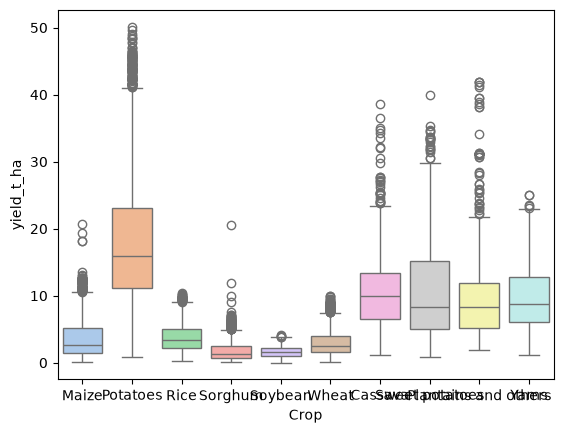

In [18]:
#Verification du rendement par culture (visualisation) - yield_merged
sns.boxplot(
    y=yield_merged["yield_t_ha"],
    x=yield_merged["Crop"],
    palette="pastel")

In [19]:
#Vérification du rendement par culture avec détection des outliers (détection des outliers par IQR)
#Calcul des quantiles
# Détection des outliers par IQR, culture par culture
rendement_par_culture = yield_merged.groupby("Crop")["yield_t_ha"]
Q1 = rendement_par_culture.quantile(0.25)
Q3 = rendement_par_culture.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR    # une borne par culture
higher_bound = Q3 + 1.5 * IQR

# Chaque ligne reçoit les bornes de sa culture
borne_basse = yield_merged["Crop"].map(lower_bound)
borne_haute = yield_merged["Crop"].map(higher_bound)

outliers_yield_merged = yield_merged[
    (yield_merged["yield_t_ha"] < borne_basse) |
    (yield_merged["yield_t_ha"] > borne_haute)
]
print(len(outliers_yield_merged))
print(outliers_yield_merged["Crop"].value_counts())
display(outliers_yield_merged)

508
Crop
Potatoes                109
Sorghum                  99
Wheat                    91
Maize                    80
Plantains and others     44
Cassava                  30
Rice                     24
Sweet potatoes           21
Soybean                   5
Yams                      5
Name: count, dtype: int64


,Area,Crop,Year,yield_t_ha,pesticides_tonnes,average_rain_fall_mm_per_year,avg_temp
178,Algeria,Sorghum,1993,5.0000,1021.89,89.0,17.000000
184,Algeria,Sorghum,2000,6.9500,603.67,89.0,17.900000
190,Algeria,Sorghum,2006,5.6728,4110.72,89.0,18.130000
191,Algeria,Sorghum,2007,11.9059,5390.79,89.0,17.420000
192,Algeria,Sorghum,2008,6.1786,11556.12,89.0,17.550000
...,...,...,...,...,...,...,...
15432,United States of America,Potatoes,2010,44.9438,374818.20,715.0,15.064231
15433,United States of America,Potatoes,2011,44.6923,391298.70,715.0,15.338846
15434,United States of America,Potatoes,2012,45.7762,407779.20,715.0,16.111346
15435,United States of America,Potatoes,2013,46.3577,407779.20,715.0,16.438846


Nous avons dans yield_merge beaucoup de potentiels outliers. Pour être certain de ne pas supprimer des n pertinents nous allons calculer un coefficient de variation. CV = ecart-type/moyenne ( à quel point la série varie d'une année à l'autre, relativement à son propre niveau).

Nombre de séries : 718
count    717.000000
mean       0.212419
std        0.156977
min        0.000025
25%        0.109726
50%        0.173044
75%        0.270175
max        1.330983
Name: cv, dtype: float64


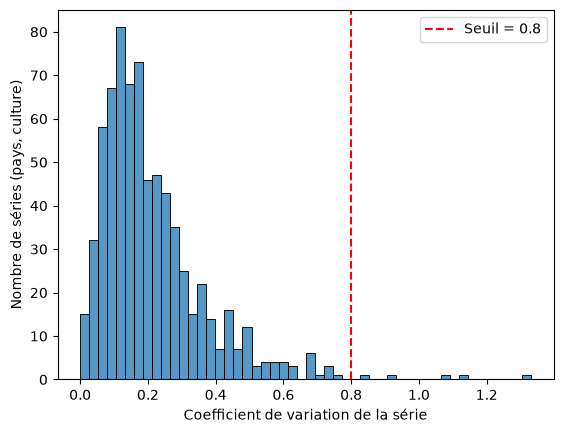

,Area,Crop,n,moyenne,ecart_type,minimum,maximum,cv
621,Tajikistan,Soybean,21,0.090881,0.120961,0.0050,0.4000,1.330983
45,Azerbaijan,Sorghum,12,0.332417,0.379172,0.0578,1.2000,1.140652
347,Kazakhstan,Sorghum,22,1.499177,1.596543,0.2258,6.5862,1.064946
271,Guyana,Sweet potatoes,17,13.767124,12.543582,1.6346,32.9827,0.911126
9,Algeria,Sorghum,23,5.253852,4.347077,1.2667,20.6000,0.827407


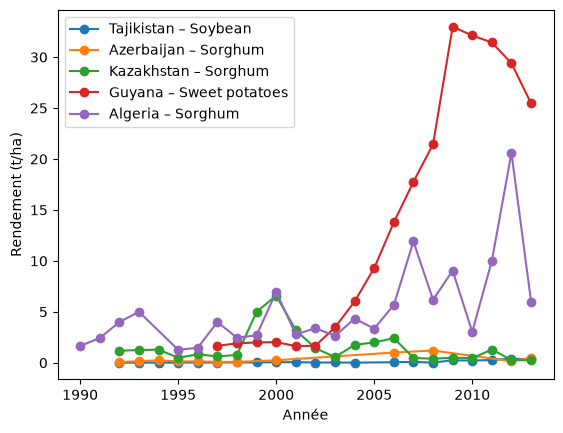

In [20]:
#Indicateurs par série (pays, culture) 
stats_series = (
    yield_merged.groupby(["Area", "Crop"])["yield_t_ha"]
    .agg(n="size", moyenne="mean", ecart_type="std", minimum="min", maximum="max")
    .reset_index()
)
stats_series["cv"] = stats_series["ecart_type"] / stats_series["moyenne"]

print("Nombre de séries :", len(stats_series))
print(stats_series["cv"].describe())

#Visualiser la distribution des CV
SEUIL_CV = 0.8
sns.histplot(stats_series["cv"], bins=50)
plt.axvline(SEUIL_CV, color="red", linestyle="--", label=f"Seuil = {SEUIL_CV}")
plt.xlabel("Coefficient de variation de la série")
plt.ylabel("Nombre de séries (pays, culture)")
plt.legend()
plt.show()

#Séries au-dessus du seuil
series_instables = stats_series.loc[stats_series["cv"] > SEUIL_CV].sort_values("cv", ascending=False)
display(series_instables)

#Visualiser ces séries dans le temps
for _, ligne in series_instables.iterrows():
    serie = yield_merged.loc[
        (yield_merged["Area"] == ligne["Area"]) & (yield_merged["Crop"] == ligne["Crop"])
    ].sort_values("Year")
    plt.plot(serie["Year"], serie["yield_t_ha"], marker="o", label=f"{ligne['Area']} – {ligne['Crop']}")
plt.xlabel("Année")
plt.ylabel("Rendement (t/ha)")
plt.legend()
plt.show()

le rendement d’un pays pour une culture évolue progressivement. Il progresse avec les techniques, il baisse lors d’une sécheresse, mais il ne passe pas de 1 à 20 t/ha. Une série réelle a généralement un CV entre 0,1 et 0,4. Un CV très élevé signale une série incohérente. On peut donc observer ici les 5 pays qui présentent un coefficient de variations très importants ainsi que la culture à laquelle cette variation élevée est associée

In [21]:
# Liste des séries à exclure, générée à partir du critère CV > 0.8
series_exclues = list(zip(series_instables["Area"], series_instables["Crop"]))
print("Séries exclues :", series_exclues)

print("Avant :", yield_merged.shape)

# Masque : True si la ligne appartient à l'une des séries exclues
masque = pd.Series(False, index=yield_merged.index)
for pays, culture in series_exclues:
    masque = masque | ((yield_merged["Area"] == pays) & (yield_merged["Crop"] == culture))

print("Lignes supprimées :", masque.sum())

# On garde tout ce qui n'est pas dans le masque
yield_merged = yield_merged.loc[~masque]
print("Après :", yield_merged.shape)

Séries exclues : [('Tajikistan', 'Soybean'), ('Azerbaijan', 'Sorghum'), ('Kazakhstan', 'Sorghum'), ('Guyana', 'Sweet potatoes'), ('Algeria', 'Sorghum')]
Avant : (16492, 7)
Lignes supprimées : 95
Après : (16397, 7)


Détection IQR par culture : 508 valeurs repérées, principalement des pays à agriculture intensive (Pays-Bas, Belgique, Nouvelle-Zélande…), dont les rendements élevés sont réels : elles sont conservées. Les baisses brutales correspondent souvent à des événements réels (sécheresse de 1992 en Afrique australe) : elles sont aussi conservées. Pour repérer les séries incohérentes, on a calculé le coefficient de variation de chaque série (pays, culture). 5 séries ont un CV supérieur à 0,8, nettement isolé dans la distribution : elles ont été exclues (95 lignes, 0,6 %). Cas limite : le maïs au Qatar (valeur quasi constante pendant 17 ans) n’est pas détecté par ce critère et a été conservé.

C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\1711109348.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


<Axes: xlabel='Crop', ylabel='Yield_tons_per_hectare'>

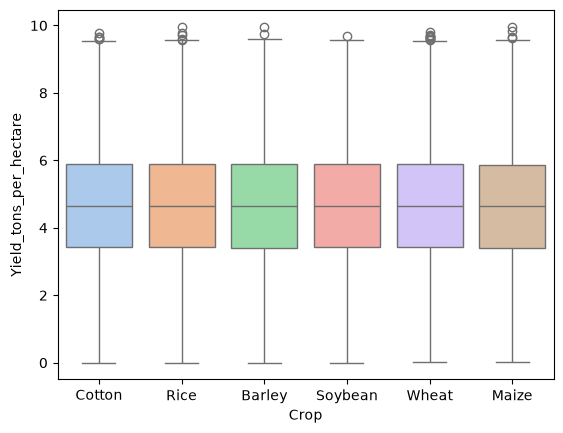

In [22]:
#Verification du rendement par culture (visualisation) - crop_yield
sns.boxplot(
    y=crop_yield_clean["Yield_tons_per_hectare"],
    x=crop_yield_clean["Crop"],
    palette="pastel")

On voit ici que les données de ce jeu sont synthétique avec une moyenne unique pour toutes les cultures.

In [23]:
#Vérification du rendement par culture avec détection des outliers (détection des outliers par IQR)
#Calcul des quantiles
Q1 = crop_yield_clean["Yield_tons_per_hectare"].quantile(0.25)
Q3 = crop_yield_clean["Yield_tons_per_hectare"].quantile(0.75)

#Calcul de l'IQR
IQR = Q3 - Q1
print(IQR)

#Calculs des limites
lower_bound = Q1 - 1.5*IQR
higher_bound = Q3 + 1.5*IQR

outliers_crop_yield = crop_yield_clean[
    (crop_yield_clean["Yield_tons_per_hectare"] < lower_bound) |
    (crop_yield_clean["Yield_tons_per_hectare"] > higher_bound)
]
print(outliers_crop_yield.value_counts().sum())
display(outliers_crop_yield)

2.4609069170862585
28


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
11596,West,Peaty,Wheat,957.380991,36.324216,1,1,Sunny,73,9.727004
173732,South,Clay,Rice,998.991449,22.513905,1,1,Cloudy,68,9.613384
224117,West,Silt,Barley,954.911259,34.653132,1,1,Rainy,146,9.580166
230072,North,Loam,Cotton,956.623791,39.830278,1,1,Cloudy,149,9.647672
288994,East,Loam,Wheat,965.464197,34.606854,1,1,Rainy,124,9.668197
350006,West,Loam,Barley,910.598704,38.842505,1,1,Cloudy,135,9.580710
385993,East,Clay,Rice,977.530313,30.647480,1,1,Rainy,137,9.721110
401635,West,Peaty,Wheat,937.648660,39.507361,1,1,Rainy,61,9.685660
461357,West,Clay,Barley,996.078325,36.972621,1,1,Rainy,135,9.595395
465022,East,Sandy,Wheat,978.875813,35.301038,1,1,Rainy,143,9.802534


In [24]:
cultures_yields = crop_yield_clean.groupby("Crop")["Yield_tons_per_hectare"]
Q1 = cultures_yields.quantile(0.25)
Q3 = cultures_yields.quantile(0.75)

#Calcul de l'IQR
IQR = Q3 - Q1
print(IQR)

#Calculs des limites
lower_bound = Q1 - 1.5*IQR
higher_bound = Q3 + 1.5*IQR

lower_bound_crop_yield = crop_yield_clean["Crop"].map(lower_bound)    # une borne par ligne, selon sa culture
higher_bound_crop_yield = crop_yield_clean["Crop"].map(higher_bound)

outliers = crop_yield_clean[
    (crop_yield_clean["Yield_tons_per_hectare"] < lower_bound_crop_yield) |
    (crop_yield_clean["Yield_tons_per_hectare"] > higher_bound_crop_yield)
]
print(len(outliers))

Crop
Barley     2.475362
Cotton     2.465668
Maize      2.459679
Rice       2.456722
Soybean    2.455784
Wheat      2.453493
Name: Yield_tons_per_hectare, dtype: float64
26


Après vérification, ces outliers détectés par la méthode des IQR montre en réalité des valeurs probables mais résultant en réalité des meilleures conditions de production (on remarque que chaque n récupéré est irrigué et est traité aux pesticides avec des températures élevés sauf pour une valeur à 15 degres mais qui est en condition ensoleillé.)

In [25]:
#Sauvegarde des deux datasets
yield_merged.to_csv(DATA_FILE / "yield_merged_clean.csv", index=False)
crop_yield_clean.to_csv(DATA_FILE / "crop_yield_clean.csv", index=False)

### Data-visualisation

C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\4027285731.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=crop_yield_clean, x=col, ax=ax, palette="pastel")
C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\4027285731.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=crop_yield_clean, x=col, ax=ax, palette="pastel")
C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\4027285731.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=crop_yield_clean, x=col, ax=ax, palette="pastel")
C:\Users\Cheun\AppData\Local\Temp\

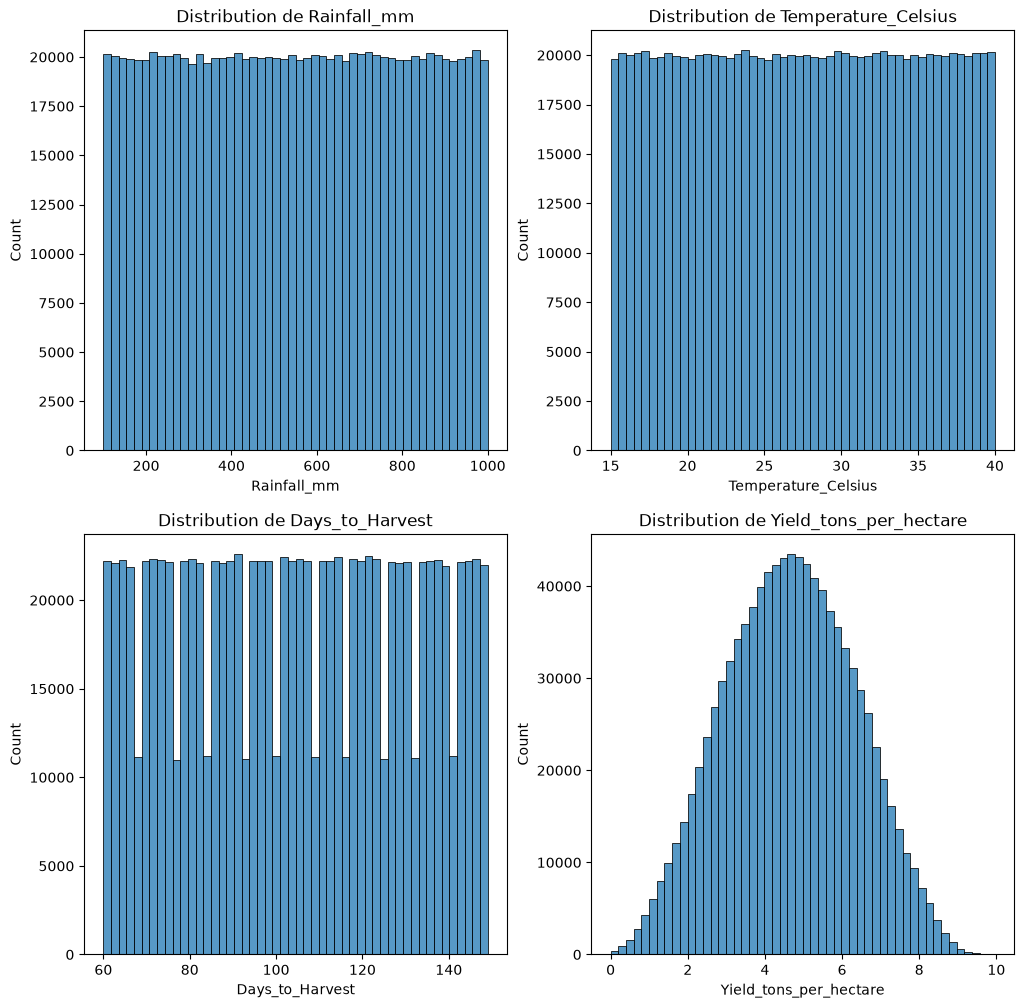

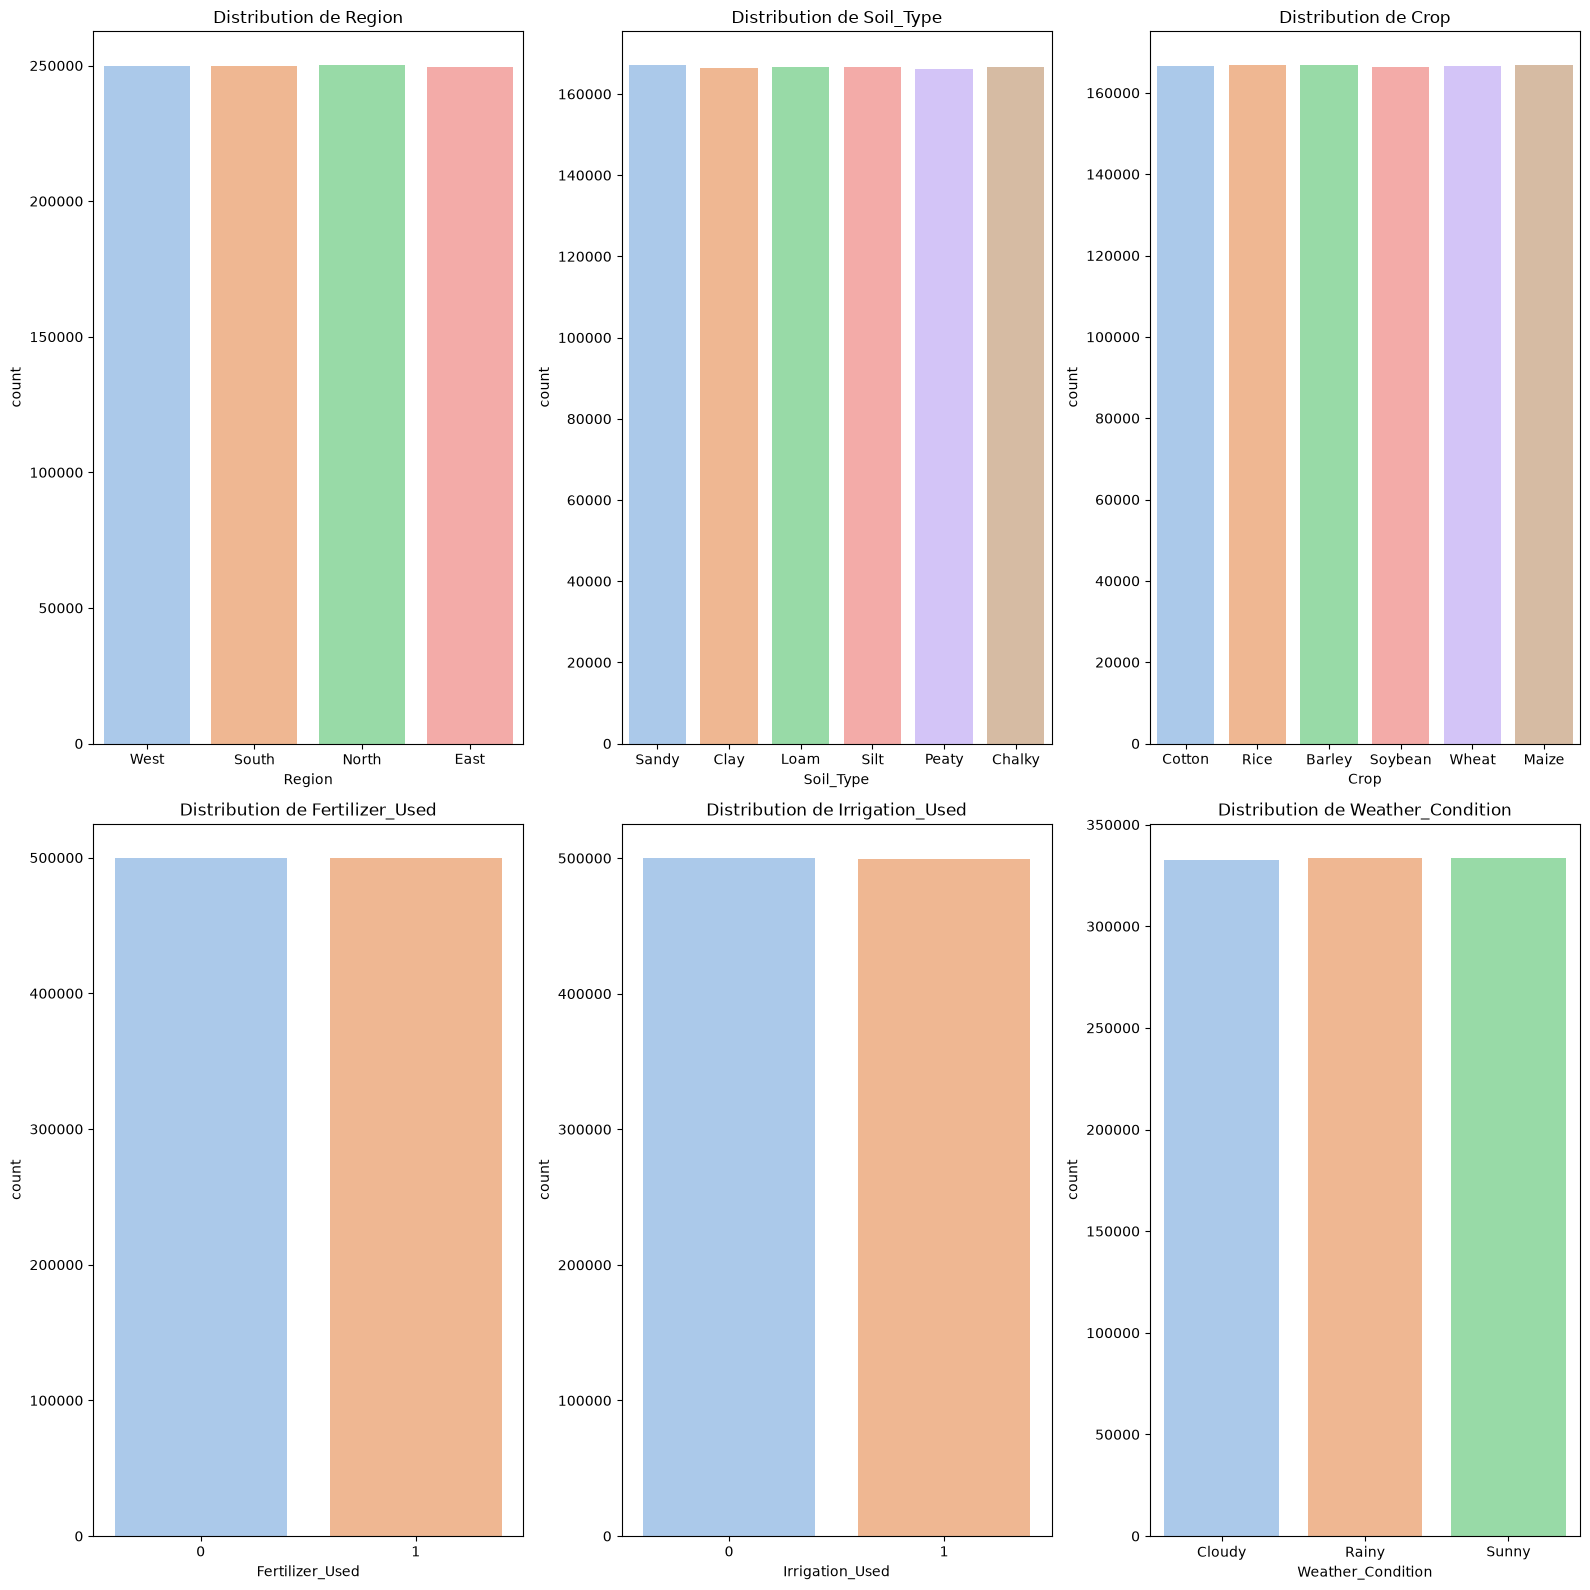

In [26]:
#DataViz crop_yield
numeric_columns_crop_yield = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", "Yield_tons_per_hectare"]
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, col in zip(axes.flatten(), numeric_columns_crop_yield):
    sns.histplot(data=crop_yield_clean, x=col, bins=50, ax=ax)
    ax.set_title(f"Distribution de {col}")

categorical_columns_crop_yield = ["Region", "Soil_Type", "Crop", "Fertilizer_Used", "Irrigation_Used", "Weather_Condition"]
fig, axes = plt.subplots(2, 3, figsize=(16,16))
for ax, col in zip(axes.flatten(), categorical_columns_crop_yield):
    sns.countplot(data=crop_yield_clean, x=col, ax=ax, palette="pastel")
    ax.set_title(f"Distribution de {col}")

plt.tight_layout()
plt.show()

Toutes les variables explicatives de crop_yield suivent des distributions uniformes : les variables continues sont réparties également entre leurs bornes, et les variables catégorielles sont parfaitement équilibrées. Cette structure est caractéristique de données générées artificiellement : dans des données réelles, certaines cultures, sols ou climats seraient plus fréquents que d’autres. Seule la cible (rendement) suit une distribution en cloche, ce qui suggère qu’elle a été calculée à partir des autres variables, avec un bruit aléatoire.

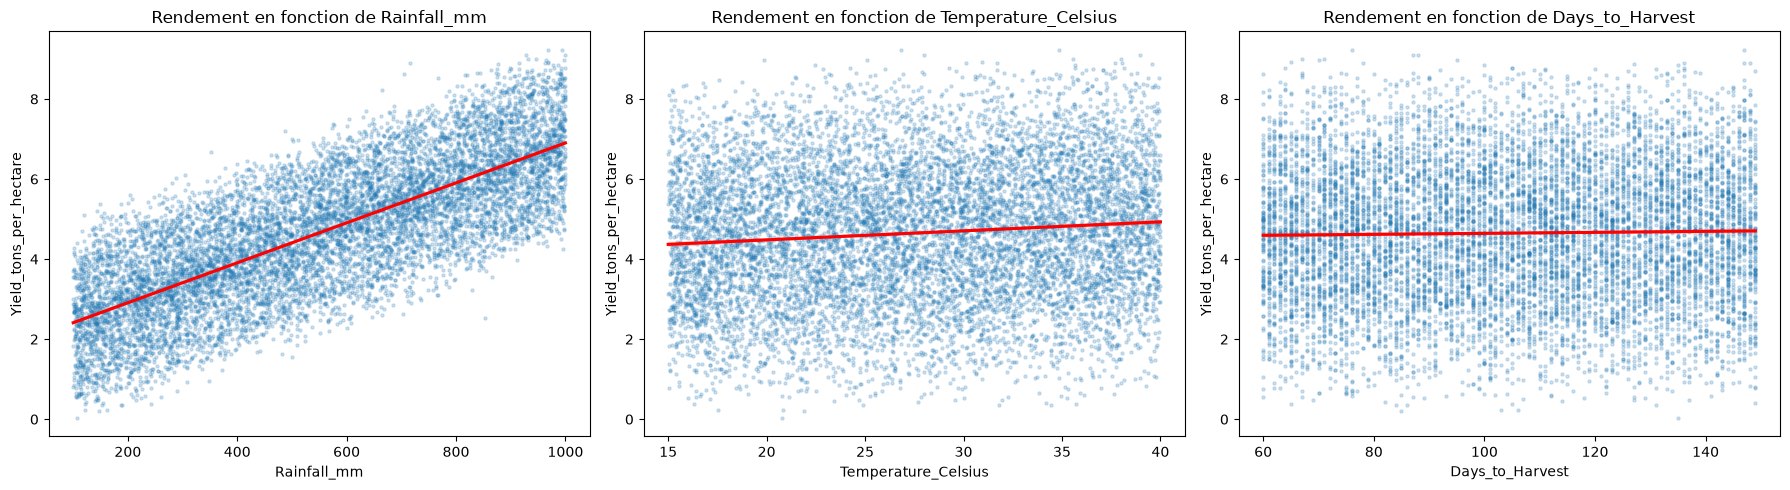

In [27]:
echantillon = crop_yield_clean.sample(n=10000, random_state=42)
variables_numeriques = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes.flatten(), variables_numeriques):
    sns.regplot(
        data=echantillon, x=col, y="Yield_tons_per_hectare", ax=ax,
        scatter_kws={"alpha": 0.2, "s": 5}, line_kws={"color": "red"}
    )
    ax.set_title(f"Rendement en fonction de {col}")
plt.tight_layout()
plt.show()

C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\2224125976.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=echantillon, x=col, y="Yield_tons_per_hectare", ax=ax, palette="pastel")
C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\2224125976.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=echantillon, x=col, y="Yield_tons_per_hectare", ax=ax, palette="pastel")
C:\Users\Cheun\AppData\Local\Temp\ipykernel_28468\2224125976.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=echantillon, x=col, y="Yield_tons_per_hectare",

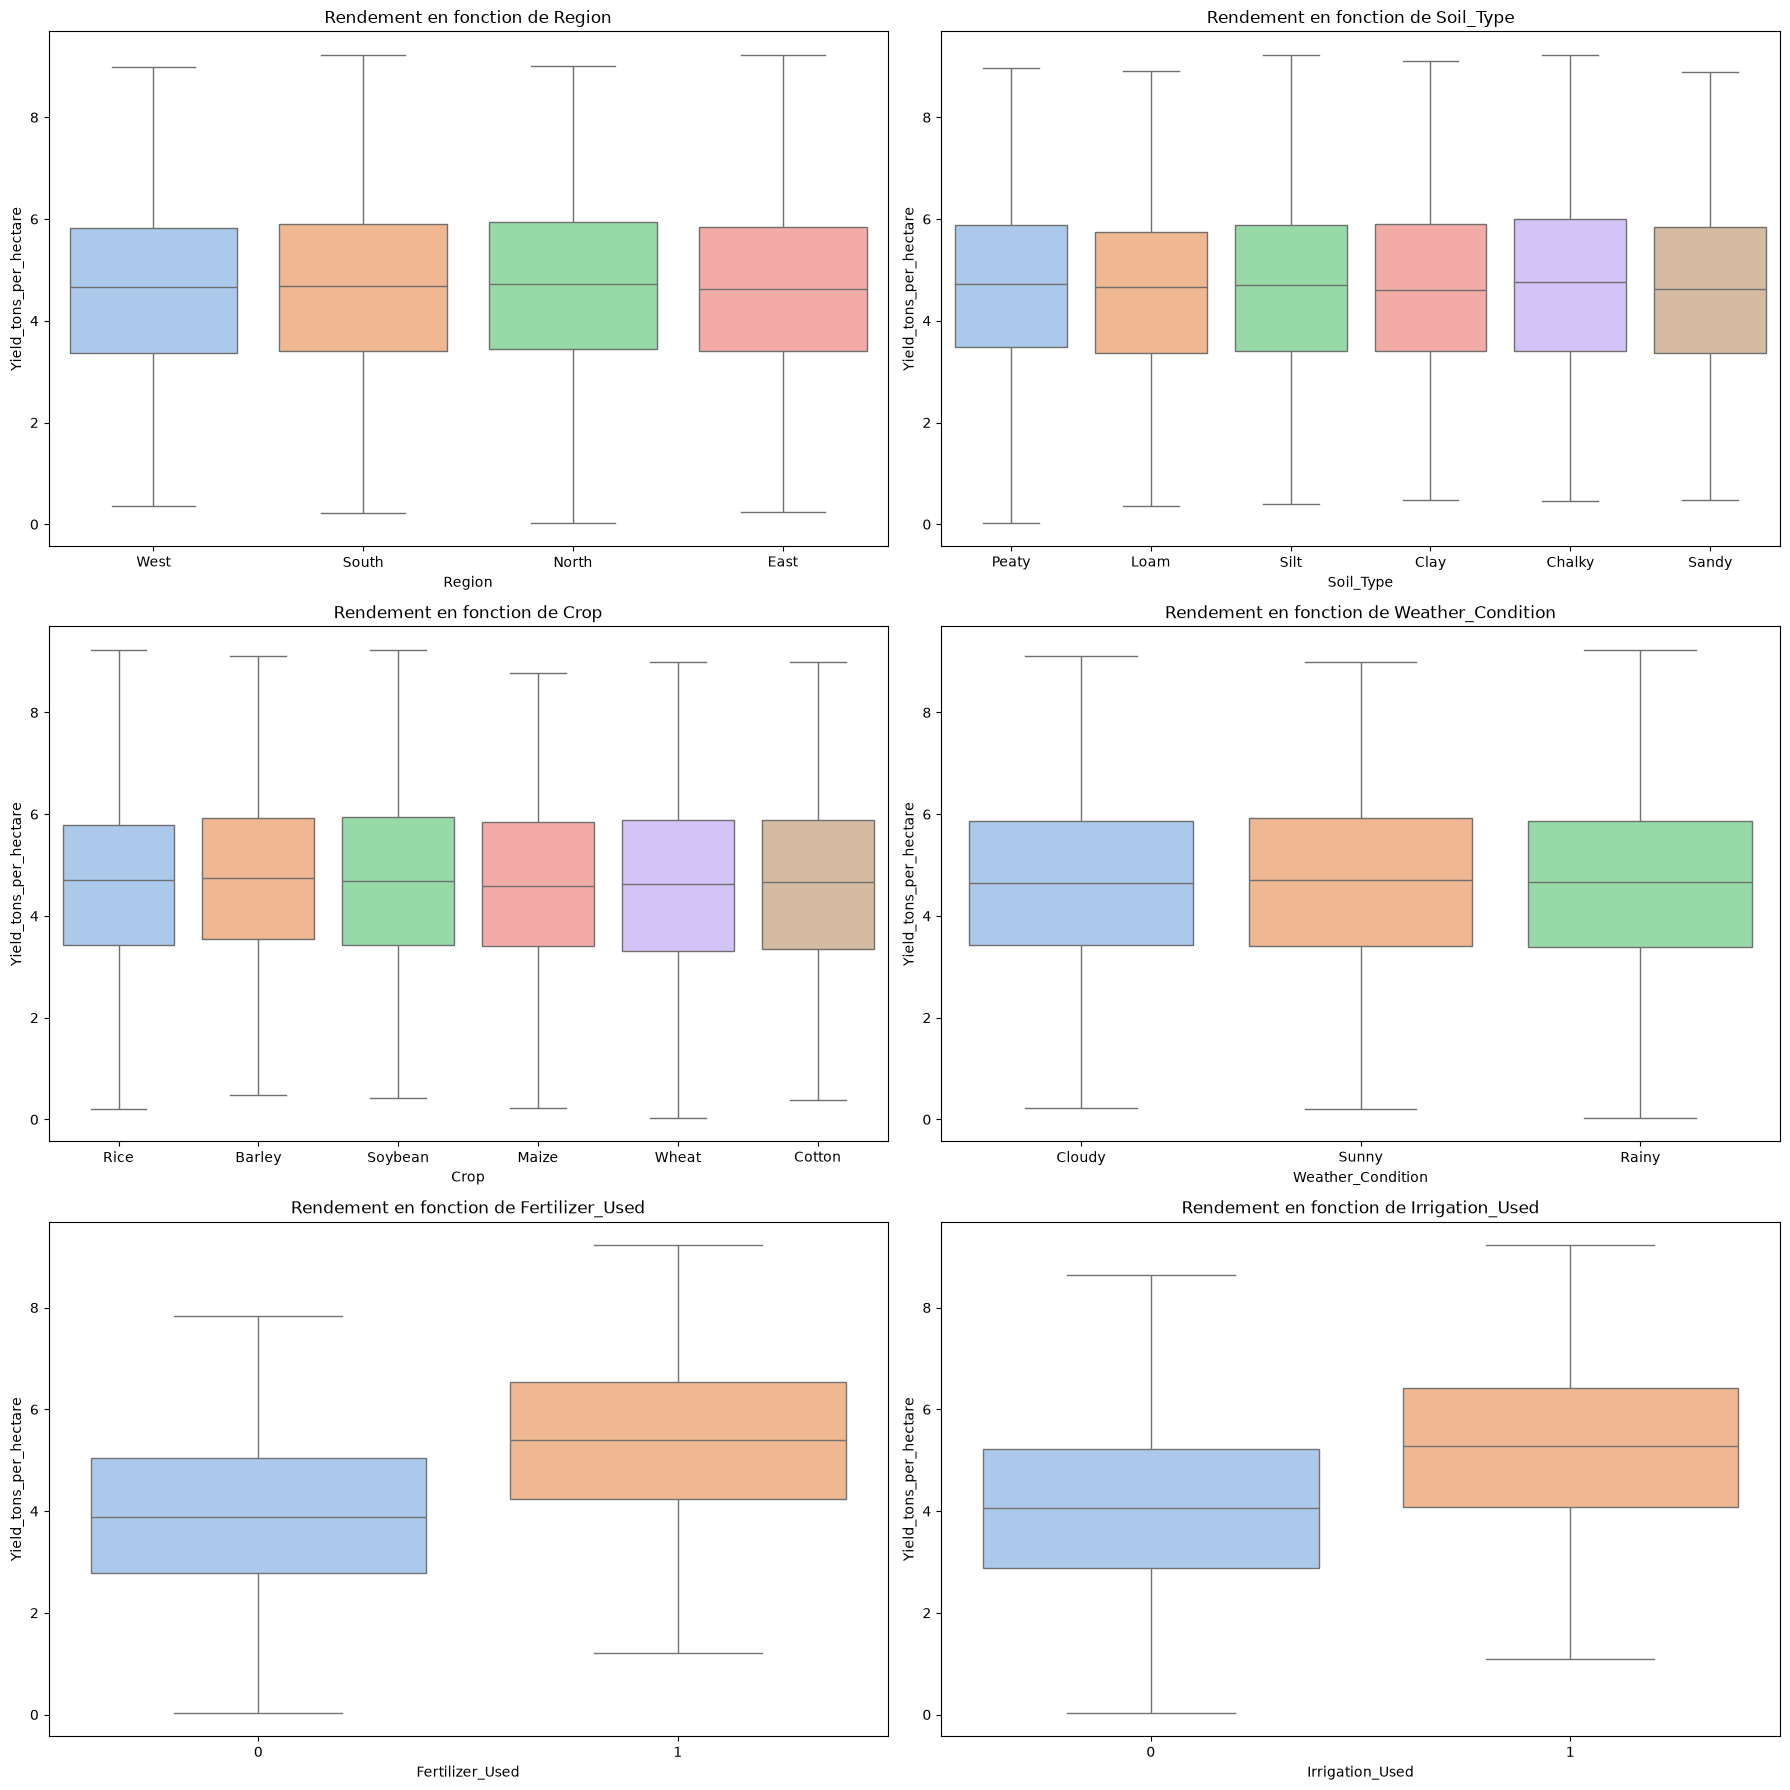

In [28]:
variables_catégorielles = ["Region", "Soil_Type", "Crop", "Weather_Condition", "Fertilizer_Used", "Irrigation_Used"]

fig, axes = plt.subplots(3, 2, figsize=(18, 18))
for ax, col in zip(axes.flatten(), variables_catégorielles):
    sns.boxplot(data=echantillon, x=col, y="Yield_tons_per_hectare", ax=ax, palette="pastel")
    ax.set_title(f"Rendement en fonction de {col}")
plt.tight_layout()
plt.show()

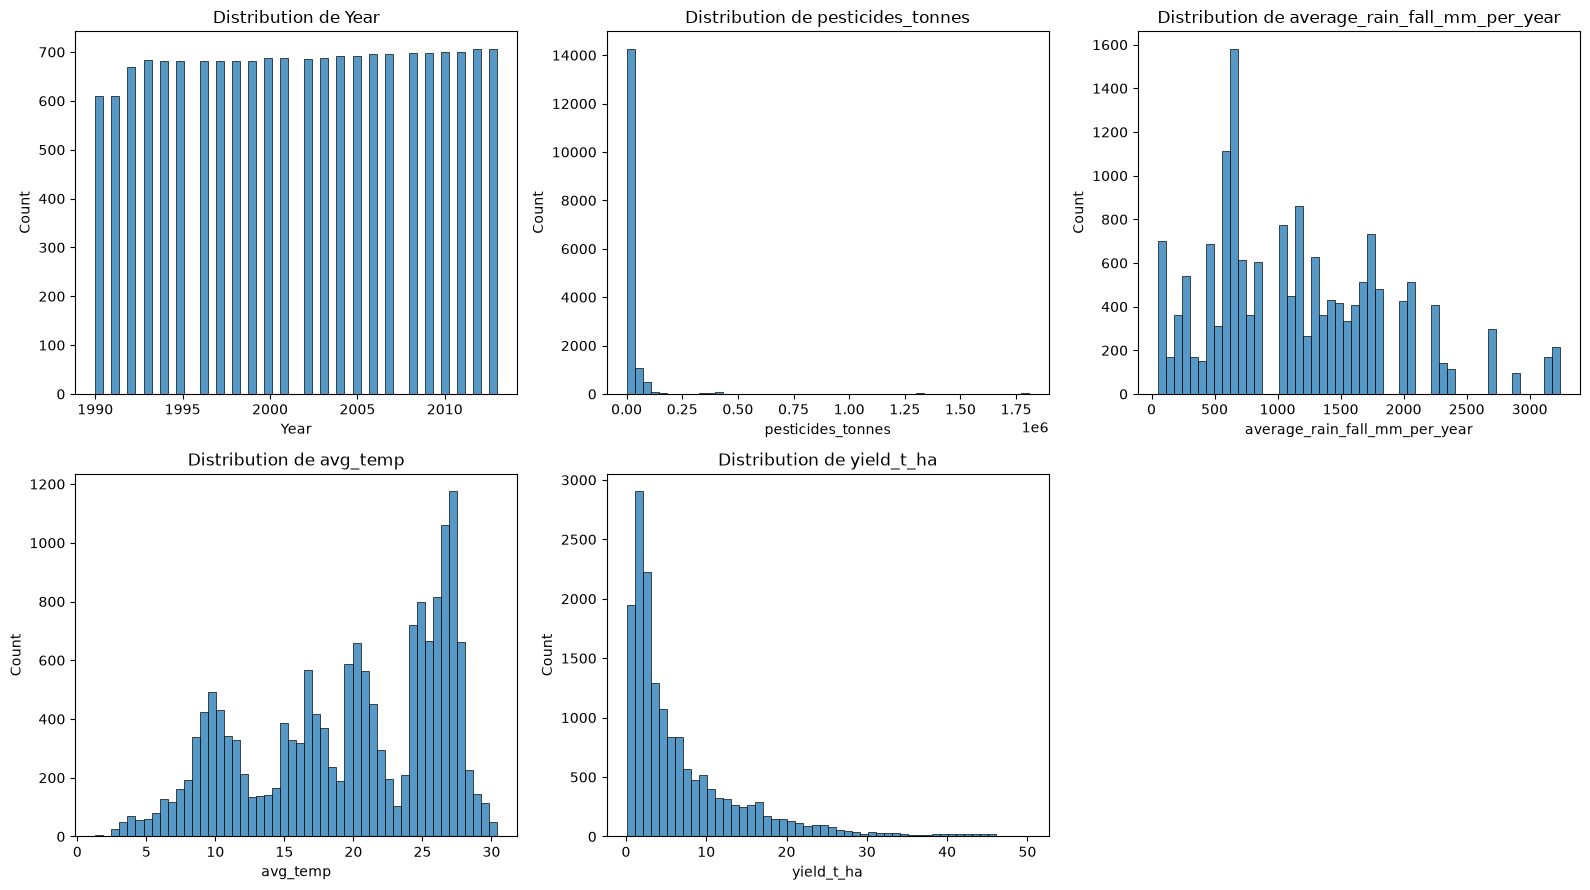

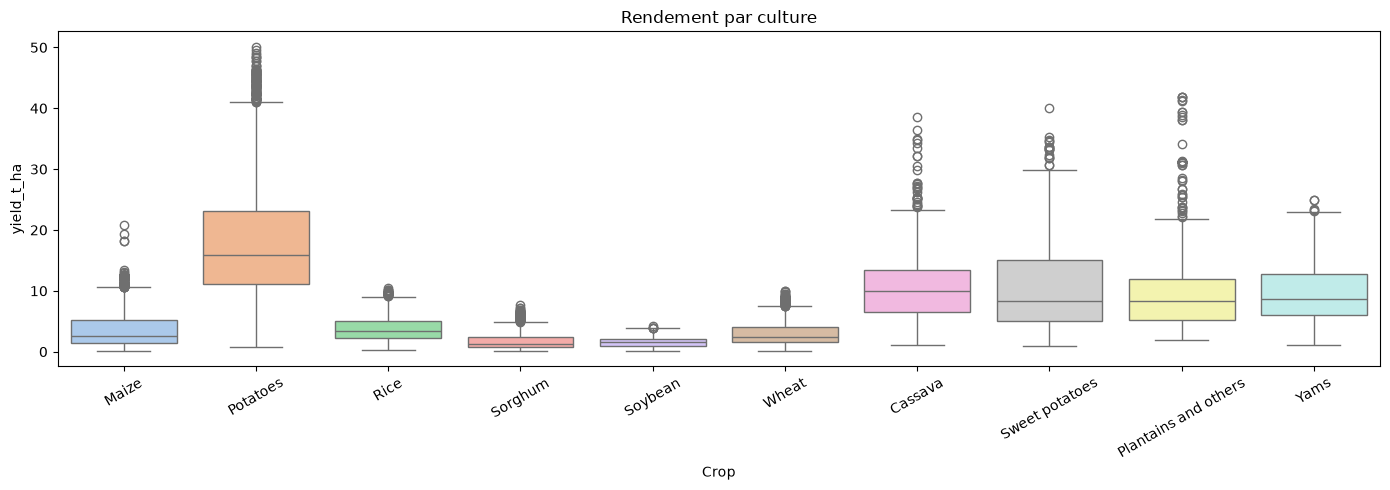

c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


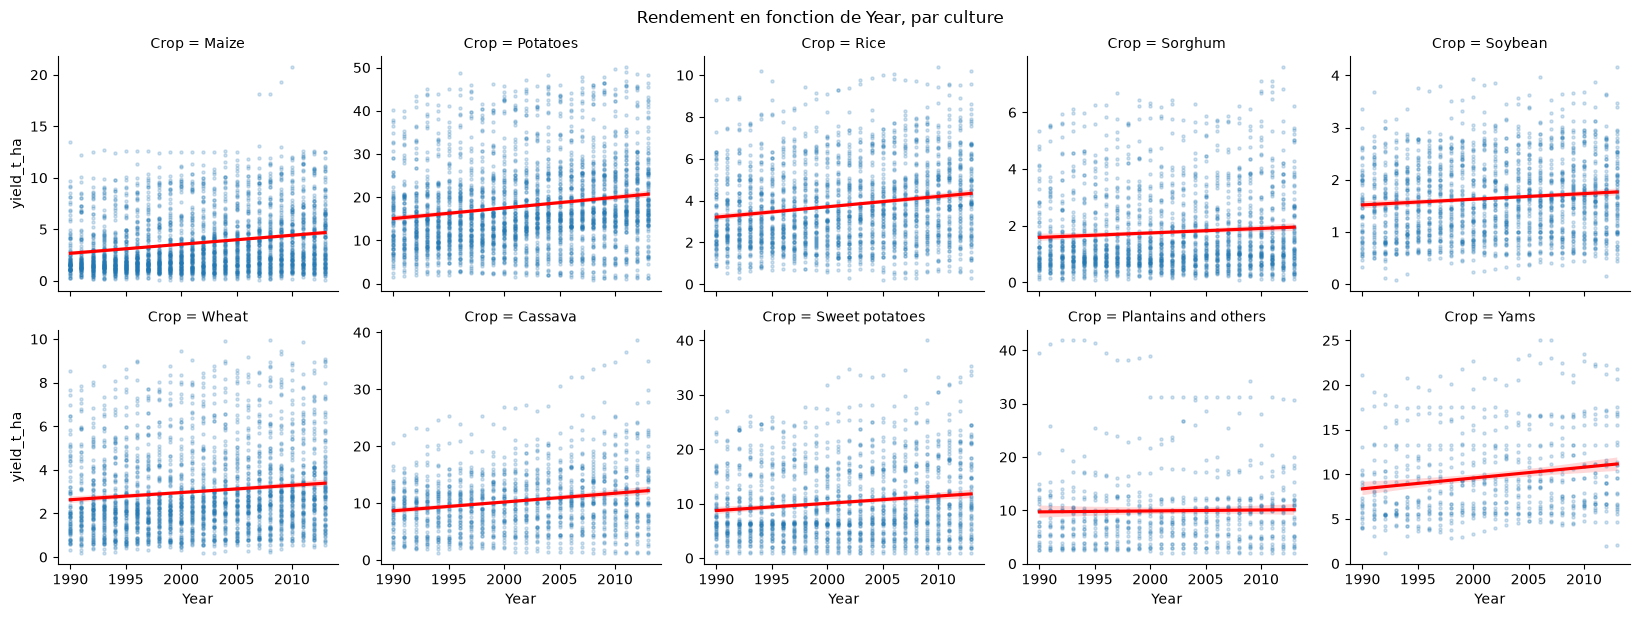

c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


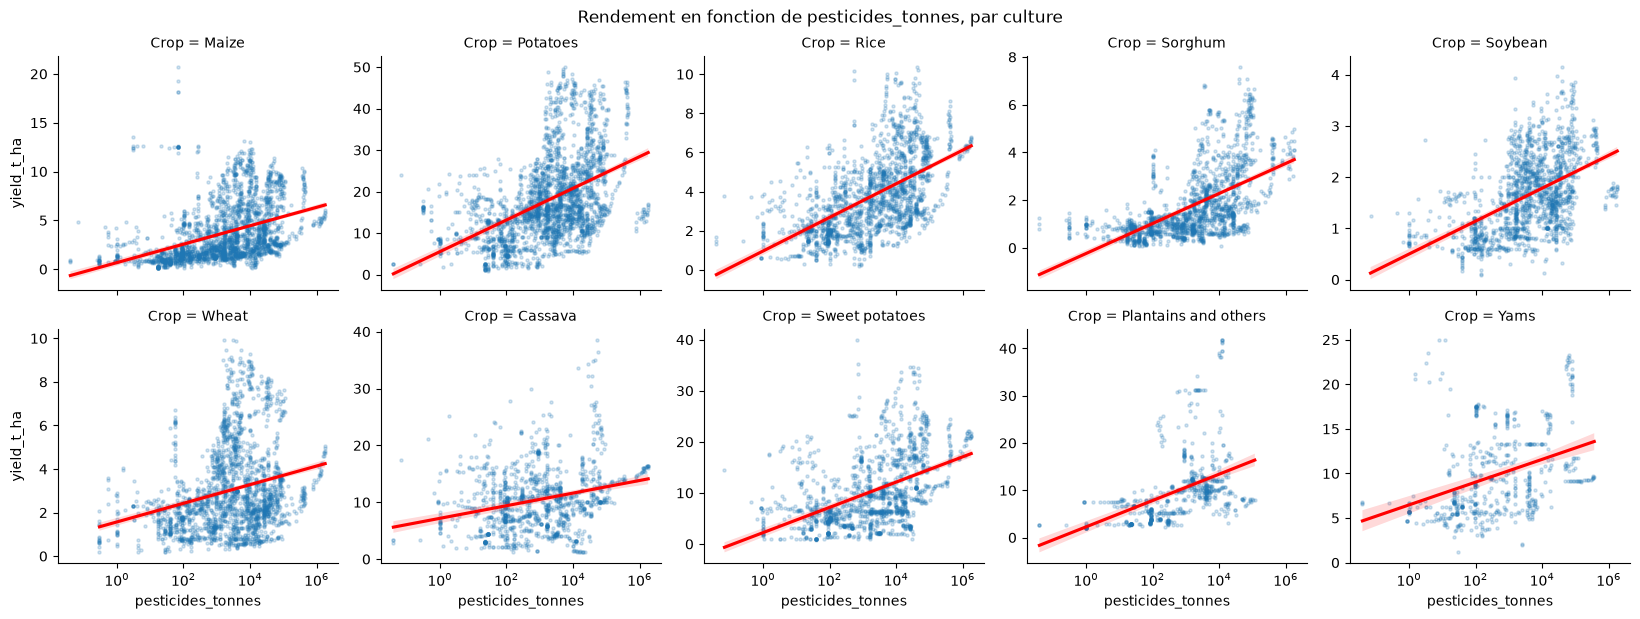

c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


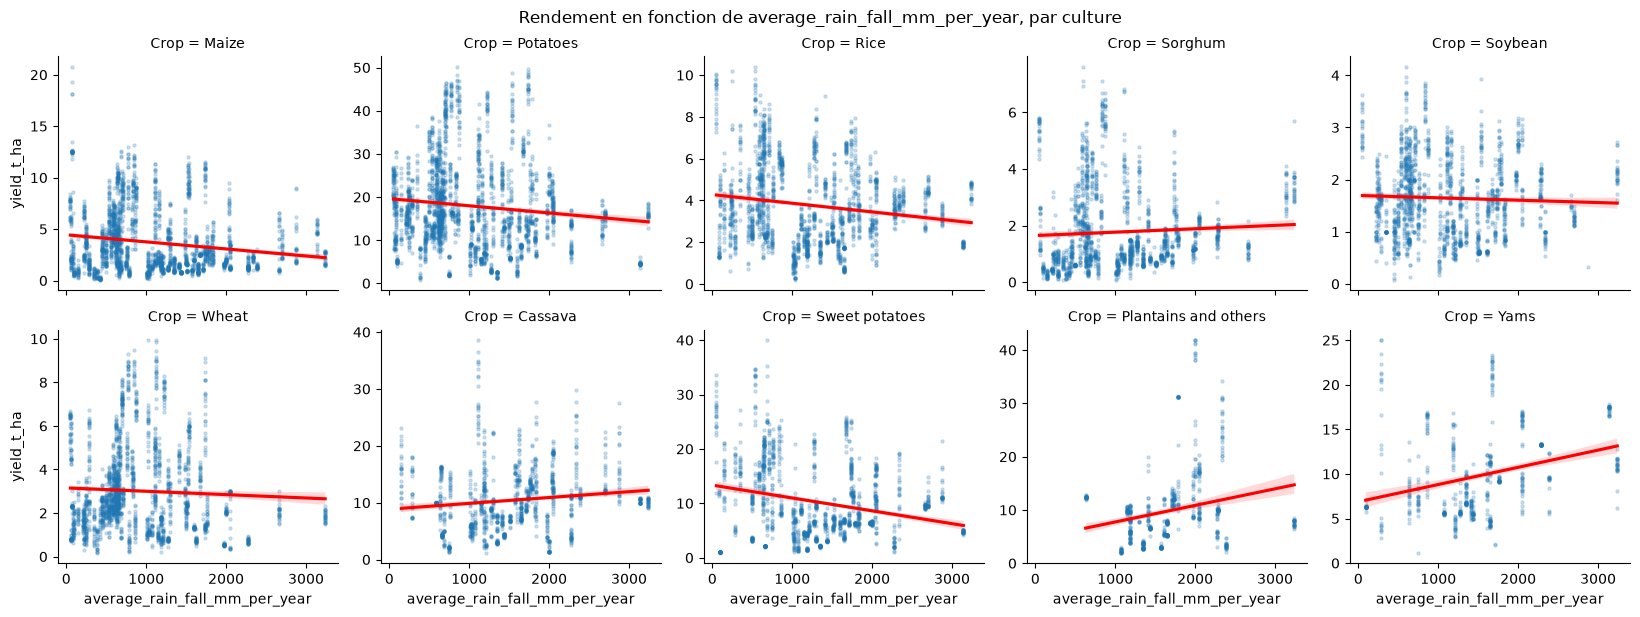

c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


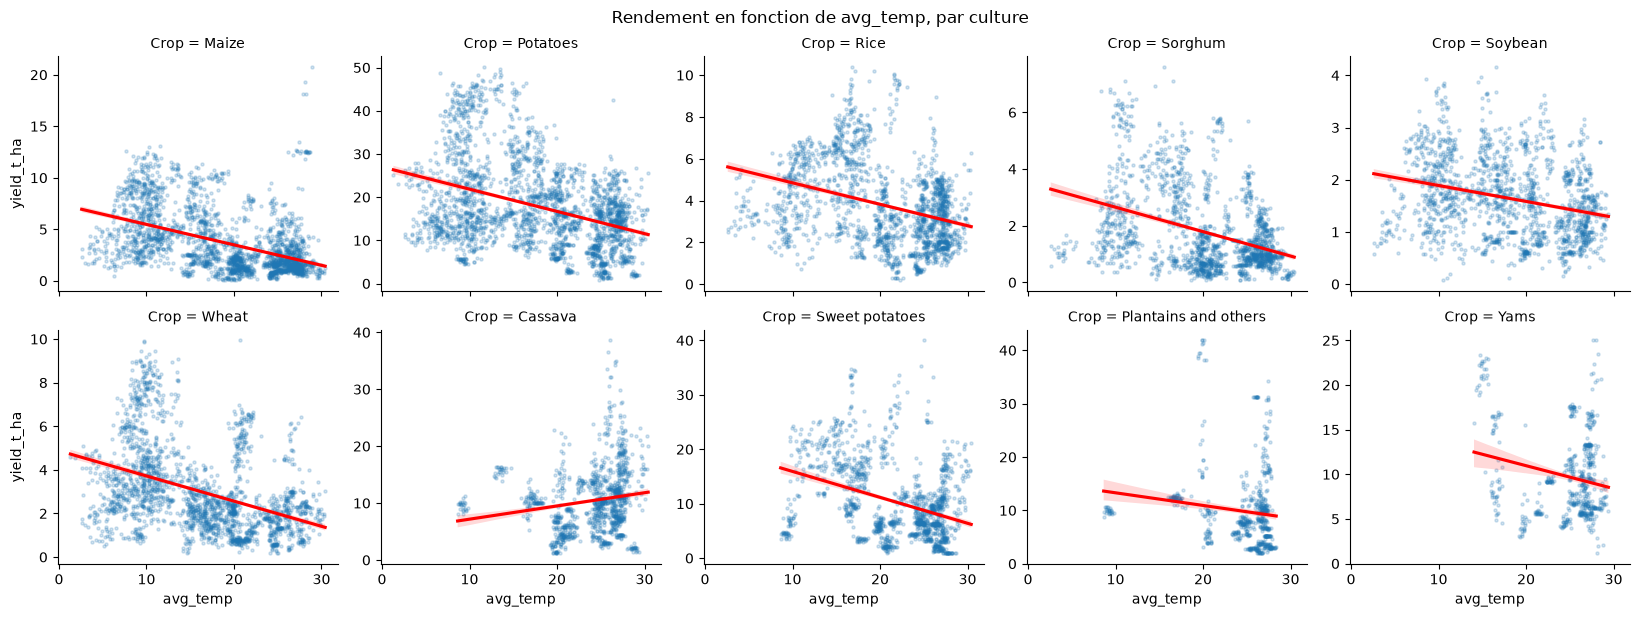

In [29]:
#DataViz yield_merged
variables_numeriques_yield = ["Year", "pesticides_tonnes", "average_rain_fall_mm_per_year", "avg_temp"]

#Distributions des variables numériques
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), variables_numeriques_yield + ["yield_t_ha"]):
    sns.histplot(data=yield_merged, x=col, bins=50, ax=ax)
    ax.set_title(f"Distribution de {col}")
axes.flatten()[-1].set_visible(False)  # 5 graphiques pour 6 emplacements : on masque le dernier
plt.tight_layout()
plt.show()

#Rendement par culture
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=yield_merged, x="Crop", y="yield_t_ha", hue="Crop", palette="pastel", legend=False, ax=ax)
ax.set_title("Rendement par culture")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

#Rendement en fonction de chaque variable, culture par culture
for col in variables_numeriques_yield:
    g = sns.lmplot(
        data=yield_merged, x=col, y="yield_t_ha",
        col="Crop", col_wrap=5, sharey=False, sharex=True,
        height=3, aspect=1.1,
        logx=(col == "pesticides_tonnes"),  # relation log pour les pesticides
        scatter_kws={"alpha": 0.2, "s": 5}, line_kws={"color": "red"},
    )
    if col == "pesticides_tonnes":
        g.set(xscale="log")
    g.fig.suptitle(f"Rendement en fonction de {col}, par culture", y=1.02)
    plt.show()

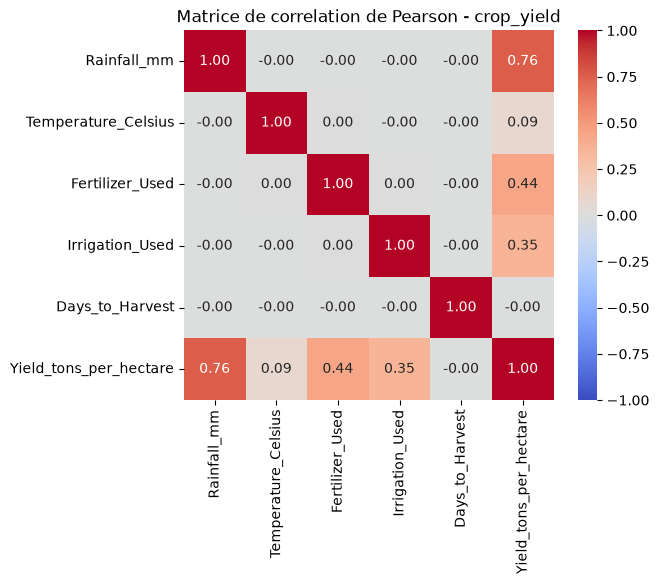

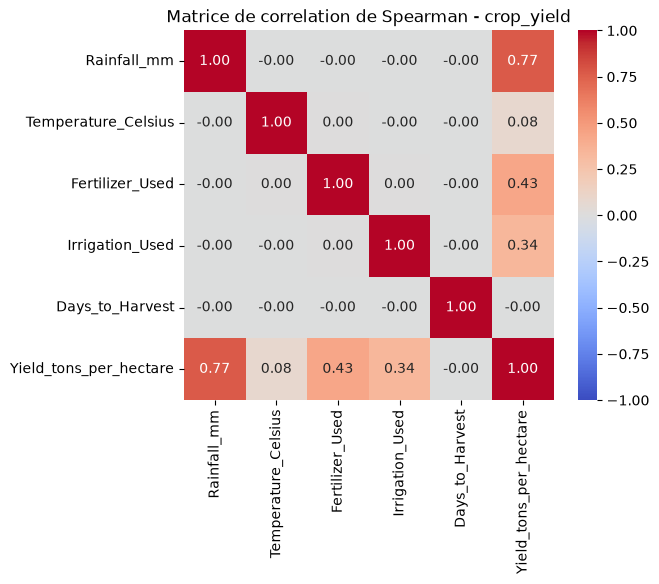

In [30]:
#heatmaps crop_yield
corr_matrix_P_crop = crop_yield_clean.corr(method="pearson", numeric_only=True)
corr_matrix_S_crop = crop_yield_clean.corr(method="spearman", numeric_only = True)
sns.heatmap(
    data=corr_matrix_P_crop,
    cmap="coolwarm",
    square=True,
    vmin=-1,
    vmax=1,
    center=0,
    annot= True,
    fmt=".2f"
    )
plt.title("Matrice de correlation de Pearson - crop_yield")
plt.show()
sns.heatmap(
    data=corr_matrix_S_crop,
    cmap="coolwarm",
    square=True,
    vmin=-1,
    vmax=1,
    center=0,
    annot= True,
    fmt=".2f"
    )
plt.title("Matrice de correlation de Spearman - crop_yield")
plt.show()


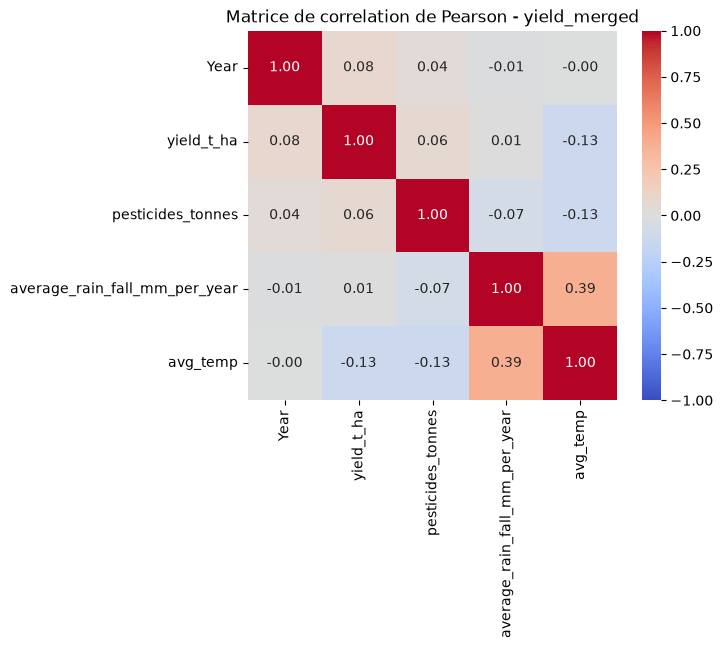

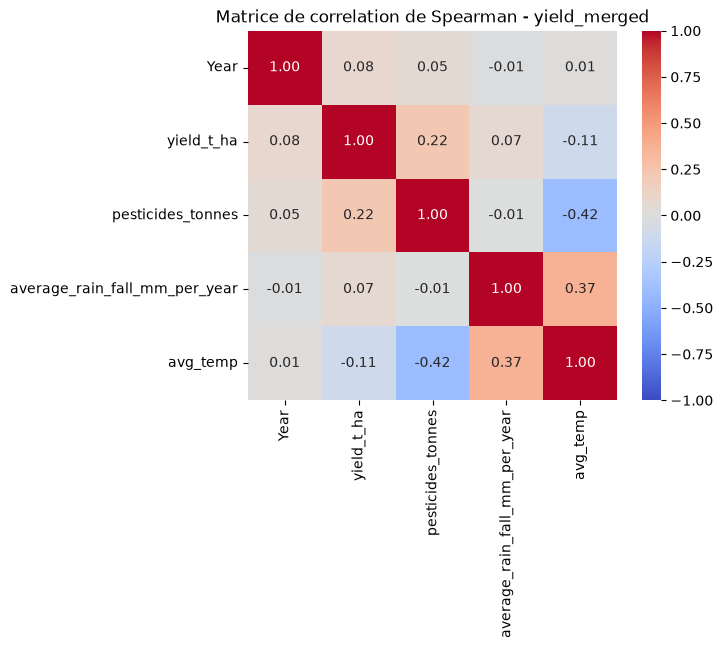

In [31]:
#heatmaps yield_merged
corr_matrix_P_yield = yield_merged.corr(method="pearson", numeric_only=True)
corr_matrix_S_yield = yield_merged.corr(method="spearman", numeric_only = True)
sns.heatmap(
    data=corr_matrix_P_yield,
    cmap="coolwarm",
    square=True,
    vmin=-1,
    vmax=1,
    center=0,
    annot= True,
    fmt=".2f"
    )
plt.title("Matrice de correlation de Pearson - yield_merged")
plt.show()
sns.heatmap(
    data=corr_matrix_S_yield,
    cmap="coolwarm",
    square=True,
    vmin=-1,
    vmax=1,
    center=0,
    annot= True,
    fmt=".2f"
    )
plt.title("Matrice de correlation de Spearman - yield_merged")
plt.show()


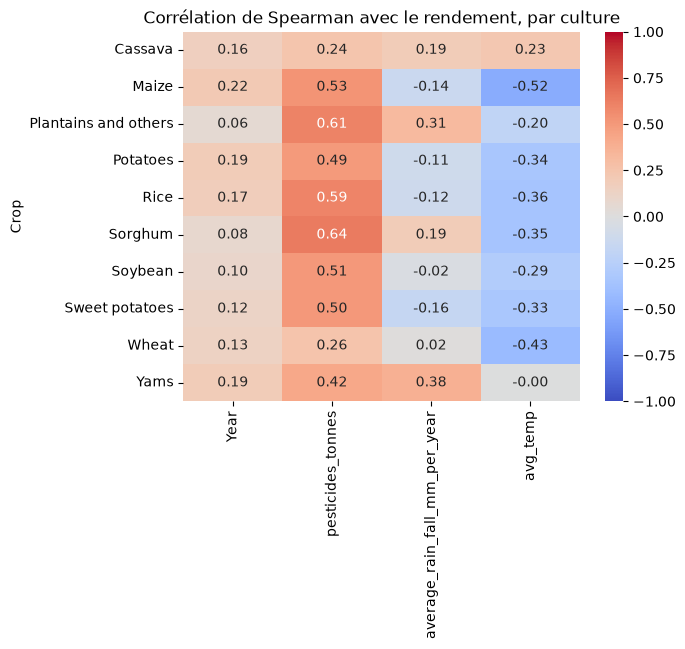

In [32]:
variables_yield = ["Year", "pesticides_tonnes", "average_rain_fall_mm_per_year", "avg_temp"]
corr_par_culture = yield_merged.groupby("Crop").apply(
    lambda d: d[variables_yield].corrwith(d["yield_t_ha"], method="spearman")
)
sns.heatmap(corr_par_culture, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélation de Spearman avec le rendement, par culture")
plt.show()

Dans crop_yield, la pluie est le facteur dominant (r = 0,76). Dans les données réelles, elle n’a aucun lien systématique avec le rendement, alors que le niveau d’intrants (pesticides) et la température jouent un rôle net, une fois la culture prise en compte. Les relations de crop_yield ne se retrouvent donc pas dans les données réelles, ce qui confirme son caractère synthétique et justifie d’appuyer le modèle sur les données FAO.

### Principal componant analyses

,Valeur propre,Variance expliquée (%),Variance cumulée (%)
PC1,1.95,32.57,32.57
PC2,1.00,16.72,49.29
PC3,1.00,16.68,65.97
PC4,1.00,16.67,82.64
PC5,1.00,16.62,99.26
PC6,0.04,0.74,100.00


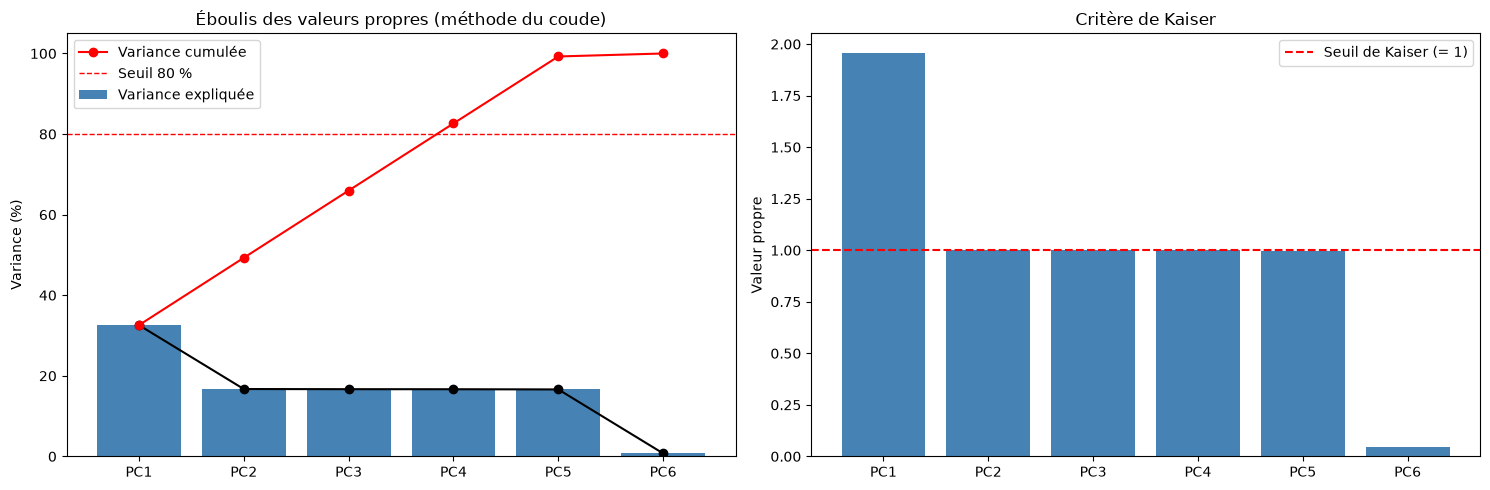

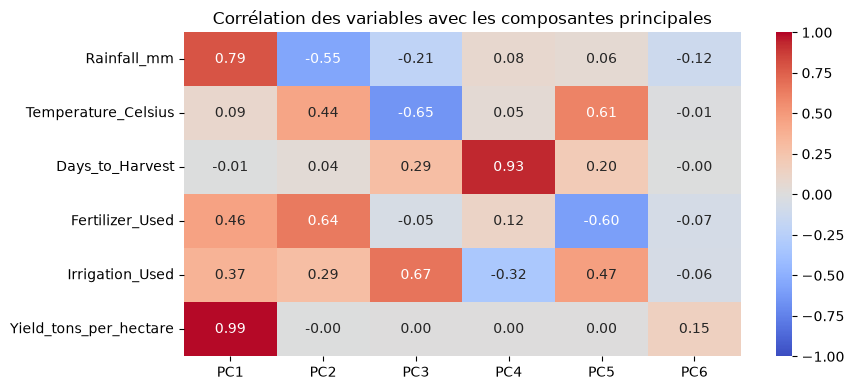

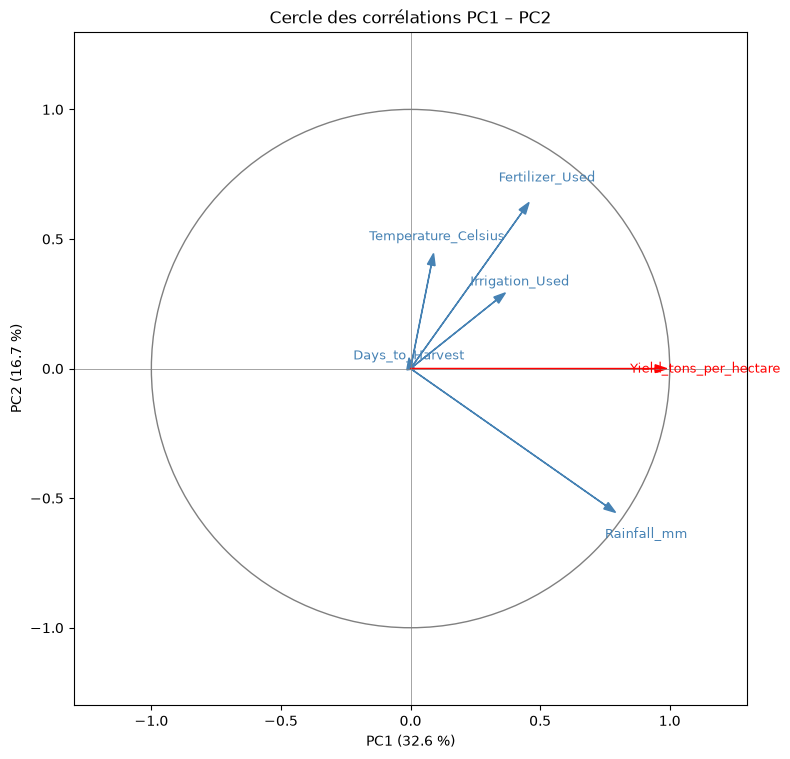

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#Données : variables explicatives + rendement (variable active)
variables_acp = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest",
                 "Fertilizer_Used", "Irrigation_Used", "Yield_tons_per_hectare"]
X = crop_yield_clean[variables_acp]

#Centrage-réduction
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=variables_acp, index=X.index)

#ACP avec toutes les composantes
pca = PCA(n_components=len(variables_acp), random_state=42)
X_pca = pca.fit_transform(X_scaled)
noms_pc = [f"PC{i+1}" for i in range(pca.n_components_)]

#Variance expliquée et valeurs propres 
variance = pd.DataFrame({
    "Valeur propre": pca.explained_variance_,
    "Variance expliquée (%)": pca.explained_variance_ratio_ * 100,
    "Variance cumulée (%)": np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=noms_pc)
display(variance.round(2))

#Méthode du coude + critère de Kaiser
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
ax.bar(noms_pc, variance["Variance expliquée (%)"], color="steelblue", label="Variance expliquée")
ax.plot(noms_pc, variance["Variance expliquée (%)"], color="black", marker="o")
ax.plot(noms_pc, variance["Variance cumulée (%)"], color="red", marker="o", label="Variance cumulée")
ax.axhline(80, color="red", linestyle="--", linewidth=1, label="Seuil 80 %")
ax.set_ylabel("Variance (%)")
ax.set_ylim(0, 105)
ax.set_title("Éboulis des valeurs propres (méthode du coude)")
ax.legend()

ax = axes[1]
ax.bar(noms_pc, variance["Valeur propre"], color="steelblue")
ax.axhline(1, color="red", linestyle="--", label="Seuil de Kaiser (= 1)")
ax.set_ylabel("Valeur propre")
ax.set_title("Critère de Kaiser")
ax.legend()

plt.tight_layout()
plt.show()

#Corrélations variables / composantes
correlations_variables = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=variables_acp, columns=noms_pc
)
plt.figure(figsize=(9, 4))
sns.heatmap(correlations_variables, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélation des variables avec les composantes principales")
plt.tight_layout()
plt.show()

#Cercle des corrélations
def cercle_correlations(axe_x, axe_y, ax):
    i, j = axe_x - 1, axe_y - 1
    ax.add_patch(plt.Circle((0, 0), 1, color="grey", fill=False))
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    for var in variables_acp:
        cx = correlations_variables.loc[var, noms_pc[i]]
        cy = correlations_variables.loc[var, noms_pc[j]]
        couleur = "red" if var == "Yield_tons_per_hectare" else "steelblue"
        ax.arrow(0, 0, cx, cy, head_width=0.03, color=couleur, length_includes_head=True)
        ax.text(cx * 1.15, cy * 1.15, var, color=couleur, ha="center", va="center", fontsize=9)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")
    ax.set_xlabel(f"{noms_pc[i]} ({pca.explained_variance_ratio_[i]*100:.1f} %)")
    ax.set_ylabel(f"{noms_pc[j]} ({pca.explained_variance_ratio_[j]*100:.1f} %)")
    ax.set_title(f"Cercle des corrélations {noms_pc[i]} – {noms_pc[j]}")

fig, ax = plt.subplots(figsize=(8, 8))
cercle_correlations(1, 2, ax)
plt.tight_layout()
plt.show()

L’ACP est réalisée sur les variables explicatives et le rendement, afin d’identifier les variables associées à la production. Le critère du coude et celui de Kaiser retiennent une seule composante (PC1, valeur propre 1,95, 32,6 % de la variance). PC1 est un axe de productivité, porté par le rendement (r = 0,99), la pluie (0,79), l’engrais (0,46) et l’irrigation (0,37). La température et la durée de culture n’y contribuent pas. Les composantes suivantes ont toutes une valeur propre de 1 : elles reflètent l’indépendance des variables explicatives et ne sont pas interprétables. Enfin, PC6 (0,7 %) révèle que le rendement est presque entièrement déterminé par une combinaison des autres variables, ce qui suggère qu’il a été généré par une formule. Variables clés retenues : pluie, engrais, irrigation.

,Valeur propre,Variance expliquée (%),Variance cumulée (%)
PC1,1.0,20.06,20.06
PC2,1.0,20.05,40.12
PC3,1.0,20.02,60.13
PC4,1.0,19.94,80.08
PC5,1.0,19.92,100.00


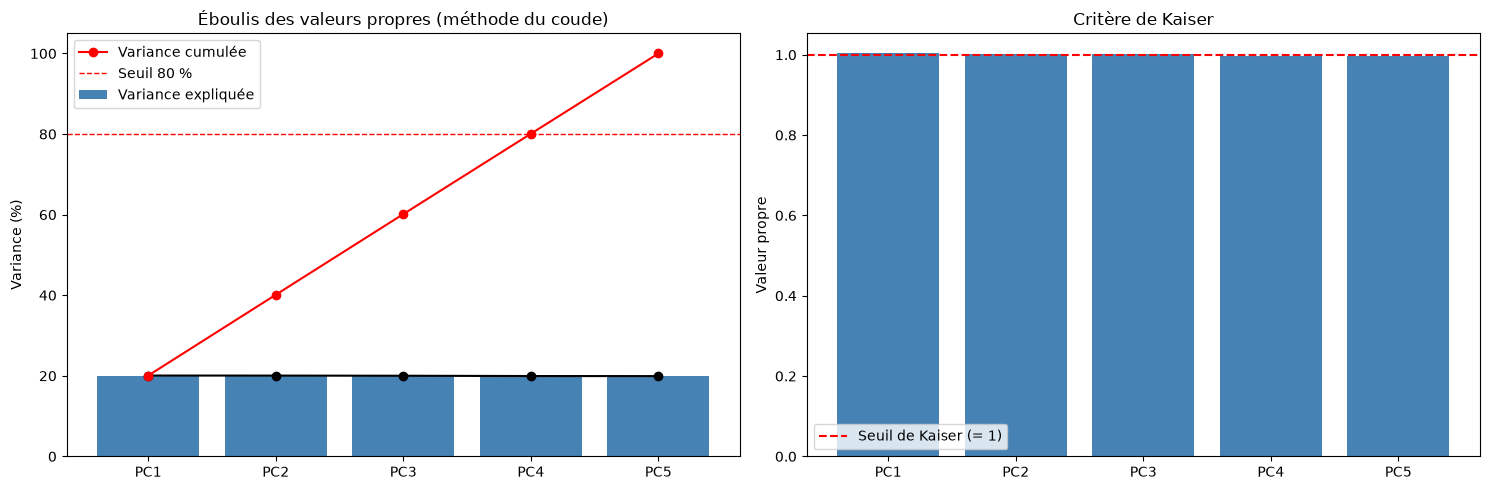

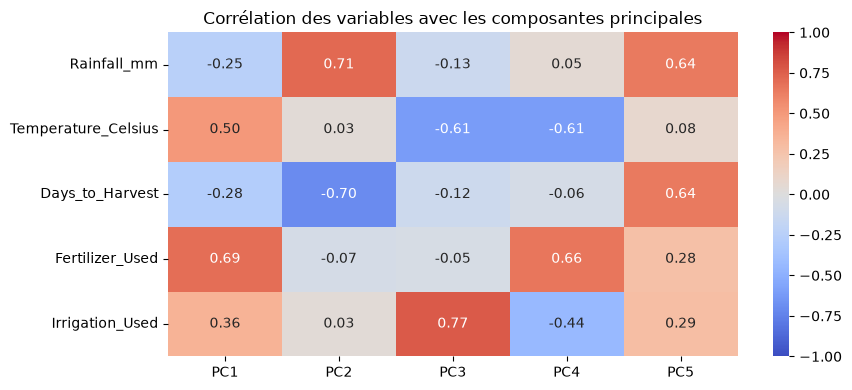

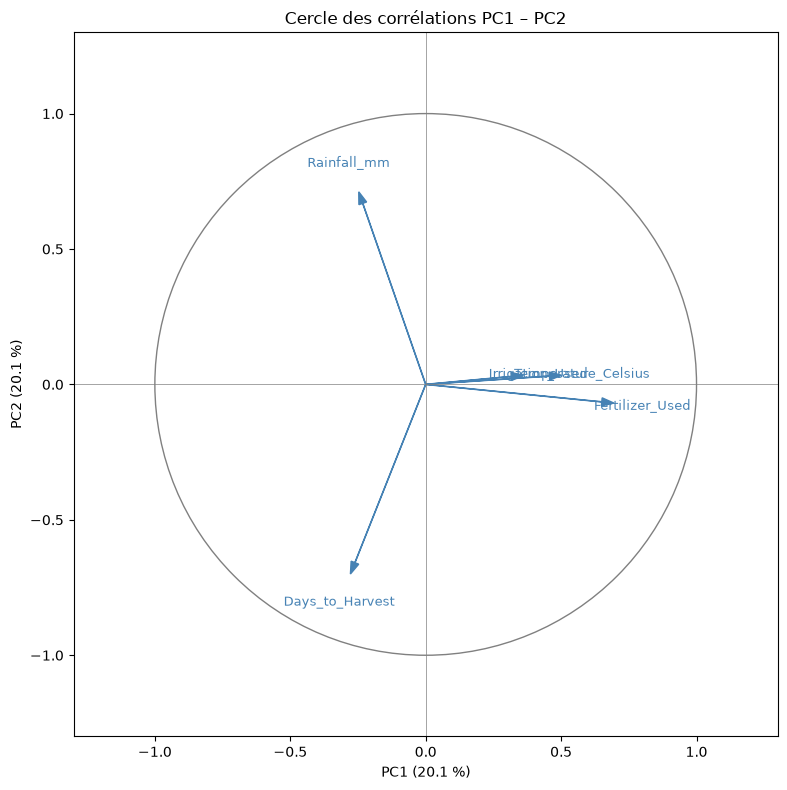

In [34]:
#Crop_yield
#Avec absence de Yield_tons_per_hectare
#Données : variables explicatives + rendement (variable active)
variables_acp = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest",
                 "Fertilizer_Used", "Irrigation_Used"]
X = crop_yield_clean[variables_acp]

#Centrage-réduction
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=variables_acp, index=X.index)

#ACP avec toutes les composantes
pca = PCA(n_components=len(variables_acp), random_state=42)
X_pca = pca.fit_transform(X_scaled)
noms_pc = [f"PC{i+1}" for i in range(pca.n_components_)]

#Variance expliquée et valeurs propres 
variance = pd.DataFrame({
    "Valeur propre": pca.explained_variance_,
    "Variance expliquée (%)": pca.explained_variance_ratio_ * 100,
    "Variance cumulée (%)": np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=noms_pc)
display(variance.round(2))

#Méthode du coude + critère de Kaiser
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
ax.bar(noms_pc, variance["Variance expliquée (%)"], color="steelblue", label="Variance expliquée")
ax.plot(noms_pc, variance["Variance expliquée (%)"], color="black", marker="o")
ax.plot(noms_pc, variance["Variance cumulée (%)"], color="red", marker="o", label="Variance cumulée")
ax.axhline(80, color="red", linestyle="--", linewidth=1, label="Seuil 80 %")
ax.set_ylabel("Variance (%)")
ax.set_ylim(0, 105)
ax.set_title("Éboulis des valeurs propres (méthode du coude)")
ax.legend()

ax = axes[1]
ax.bar(noms_pc, variance["Valeur propre"], color="steelblue")
ax.axhline(1, color="red", linestyle="--", label="Seuil de Kaiser (= 1)")
ax.set_ylabel("Valeur propre")
ax.set_title("Critère de Kaiser")
ax.legend()

plt.tight_layout()
plt.show()

#Corrélations variables / composantes
correlations_variables = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=variables_acp, columns=noms_pc
)
plt.figure(figsize=(9, 4))
sns.heatmap(correlations_variables, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélation des variables avec les composantes principales")
plt.tight_layout()
plt.show()

#Cercle des corrélations
def cercle_correlations(axe_x, axe_y, ax):
    i, j = axe_x - 1, axe_y - 1
    ax.add_patch(plt.Circle((0, 0), 1, color="grey", fill=False))
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    for var in variables_acp:
        cx = correlations_variables.loc[var, noms_pc[i]]
        cy = correlations_variables.loc[var, noms_pc[j]]
        couleur = "red" if var == "Yield_tons_per_hectare" else "steelblue"
        ax.arrow(0, 0, cx, cy, head_width=0.03, color=couleur, length_includes_head=True)
        ax.text(cx * 1.15, cy * 1.15, var, color=couleur, ha="center", va="center", fontsize=9)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")
    ax.set_xlabel(f"{noms_pc[i]} ({pca.explained_variance_ratio_[i]*100:.1f} %)")
    ax.set_ylabel(f"{noms_pc[j]} ({pca.explained_variance_ratio_[j]*100:.1f} %)")
    ax.set_title(f"Cercle des corrélations {noms_pc[i]} – {noms_pc[j]}")

fig, ax = plt.subplots(figsize=(8, 8))
cercle_correlations(1, 2, ax)
plt.tight_layout()
plt.show()

,Valeur propre,Variance expliquée (%),Variance cumulée (%)
PC1,1.43,35.83,35.83
PC2,1.02,25.41,61.24
PC3,0.94,23.52,84.76
PC4,0.61,15.24,100.00


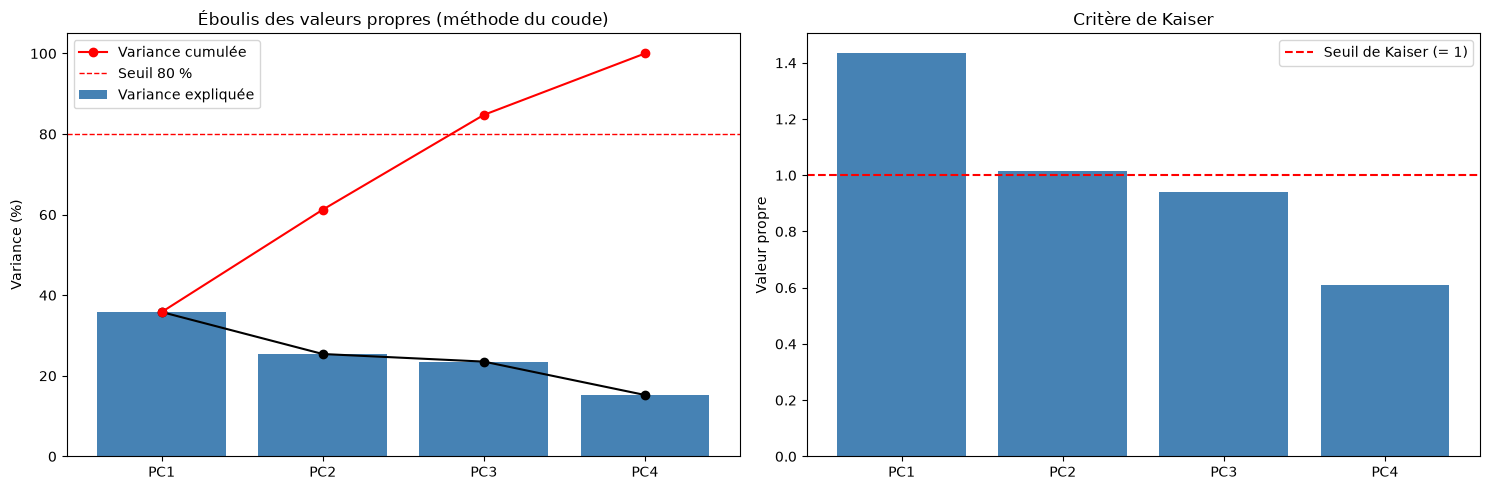

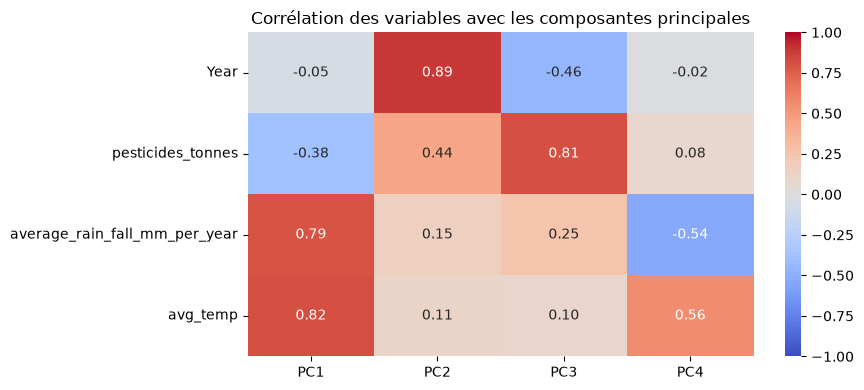

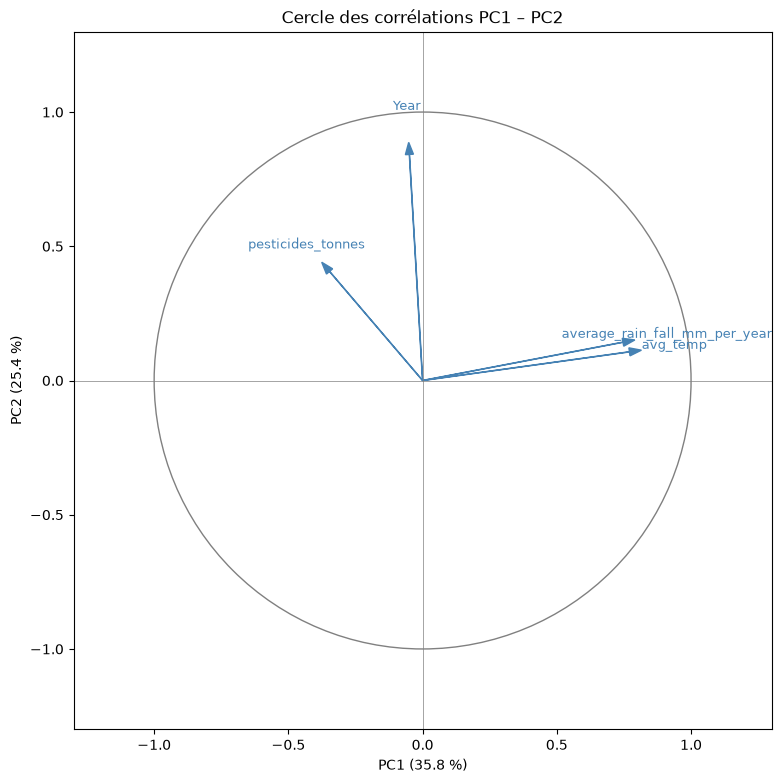

In [35]:
#yield_merged
#Avec absence du rendement
#Données : variables explicatives
variables_acp_yield = ["Year", "pesticides_tonnes", "average_rain_fall_mm_per_year", "avg_temp"]
X = yield_merged[variables_acp_yield]

#Centrage-réduction
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=variables_acp_yield, index=X.index)

#ACP avec toutes les composantes
pca = PCA(n_components=len(variables_acp_yield), random_state=42)
X_pca = pca.fit_transform(X_scaled)
noms_pc = [f"PC{i+1}" for i in range(pca.n_components_)]

#Variance expliquée et valeurs propres 
variance = pd.DataFrame({
    "Valeur propre": pca.explained_variance_,
    "Variance expliquée (%)": pca.explained_variance_ratio_ * 100,
    "Variance cumulée (%)": np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=noms_pc)
display(variance.round(2))

#Méthode du coude + critère de Kaiser
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
ax.bar(noms_pc, variance["Variance expliquée (%)"], color="steelblue", label="Variance expliquée")
ax.plot(noms_pc, variance["Variance expliquée (%)"], color="black", marker="o")
ax.plot(noms_pc, variance["Variance cumulée (%)"], color="red", marker="o", label="Variance cumulée")
ax.axhline(80, color="red", linestyle="--", linewidth=1, label="Seuil 80 %")
ax.set_ylabel("Variance (%)")
ax.set_ylim(0, 105)
ax.set_title("Éboulis des valeurs propres (méthode du coude)")
ax.legend()

ax = axes[1]
ax.bar(noms_pc, variance["Valeur propre"], color="steelblue")
ax.axhline(1, color="red", linestyle="--", label="Seuil de Kaiser (= 1)")
ax.set_ylabel("Valeur propre")
ax.set_title("Critère de Kaiser")
ax.legend()

plt.tight_layout()
plt.show()

#Corrélations variables / composantes
correlations_variables = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=variables_acp_yield, columns=noms_pc
)
plt.figure(figsize=(9, 4))
sns.heatmap(correlations_variables, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélation des variables avec les composantes principales")
plt.tight_layout()
plt.show()

#Cercle des corrélations
def cercle_correlations(correlations, pca, axe_x, axe_y, ax, cible=None):
    noms_pc = correlations.columns
    i, j = axe_x - 1, axe_y - 1
    ax.add_patch(plt.Circle((0, 0), 1, color="grey", fill=False))
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    for var in correlations.index:   # les variables viennent directement du tableau
        cx = correlations.loc[var, noms_pc[i]]
        cy = correlations.loc[var, noms_pc[j]]
        couleur = "red" if var == cible else "steelblue"
        ax.arrow(0, 0, cx, cy, head_width=0.03, color=couleur, length_includes_head=True)
        ax.text(cx * 1.15, cy * 1.15, var, color=couleur, ha="center", va="center", fontsize=9)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")
    ax.set_xlabel(f"{noms_pc[i]} ({pca.explained_variance_ratio_[i]*100:.1f} %)")
    ax.set_ylabel(f"{noms_pc[j]} ({pca.explained_variance_ratio_[j]*100:.1f} %)")
    ax.set_title(f"Cercle des corrélations {noms_pc[i]} – {noms_pc[j]}")

fig, ax = plt.subplots(figsize=(8, 8))
cercle_correlations(correlations_variables, pca, 1, 2, ax)
plt.tight_layout()
plt.show()

Contrairement à crop_yield, les variables de yield_merged sont liées entre elles. L’ACP fait apparaître un premier axe (PC1, environ 39 % de la variance, seule composante nettement retenue par Kaiser) qui oppose les pays chauds et humides à faibles intrants aux pays tempérés à agriculture intensive. L’année forme un axe indépendant (PC2). Conséquence pour la modélisation : température et pesticides étant liés, leurs effets respectifs sur le rendement seront difficiles à séparer.

Après compréhension des données et analyses poussées de celles-ci, il est clair que les données de crop_yield sont synthétiques donc très peu pertinentes pour un système de prédiction de rendement ou de prédiction de la culture la plus pertinente a développée en fonction de caractéristiques données. Pour ces raisons je continuerai ce projet seulement sur yield_merged qui est beaucoup plus pertinent.

### Feature Engineering

In [36]:
display(yield_merged)


,Area,Crop,Year,yield_t_ha,pesticides_tonnes,average_rain_fall_mm_per_year,avg_temp
0,Albania,Maize,1990,3.6613,121.00,1485.0,16.37
1,Albania,Maize,1991,2.9068,121.00,1485.0,15.36
2,Albania,Maize,1992,2.4876,121.00,1485.0,16.06
3,Albania,Maize,1993,2.4185,121.00,1485.0,16.05
4,Albania,Maize,1994,2.5848,201.00,1485.0,16.96
...,...,...,...,...,...,...,...
16487,Zimbabwe,Wheat,2009,3.0000,3269.99,657.0,20.52
16488,Zimbabwe,Wheat,2010,2.7681,3305.17,657.0,21.17
16489,Zimbabwe,Wheat,2011,2.6274,3340.35,657.0,20.78
16490,Zimbabwe,Wheat,2012,2.4420,3375.53,657.0,20.52


Je vais créer 3 variables : le log des pesticides / l'indice de De Martonne / Carré de la tempéarature et booléen sur l'usage de pesticide.
Logs des pesticides : Variable très asymétrique et relation monotone mais non linéaire avec le rendement.
Indice d'aridité de De Martonne : Indice agronomique classique qui combine pluie et température en une mesure de la disponibilité de l'eau (pluie/température + 10).
Température au carré : Chaque culture a une température optimale permettant de maximiser le rendement. En réalité, le rendement monte puis baisse quand il fait trop chaud. La relation est alors en cloche difficile à capter pour un modèle linéaire.
Booléen sur l'usage de pesticide : Pour se rapprocher des données présentes dans crop_yield.

In [37]:
yield_merged["log_pesticides"] = np.log1p(yield_merged["pesticides_tonnes"])
yield_merged["I_DeMartonne"] = (yield_merged["average_rain_fall_mm_per_year"]/(yield_merged["avg_temp"] + 10))
yield_merged["temp_sqr"] = yield_merged["avg_temp"]*yield_merged["avg_temp"]
display(yield_merged)

,Area,Crop,Year,yield_t_ha,pesticides_tonnes,average_rain_fall_mm_per_year,avg_temp,log_pesticides,I_DeMartonne,temp_sqr
0,Albania,Maize,1990,3.6613,121.00,1485.0,16.37,4.804021,56.313993,267.9769
1,Albania,Maize,1991,2.9068,121.00,1485.0,15.36,4.804021,58.556782,235.9296
2,Albania,Maize,1992,2.4876,121.00,1485.0,16.06,4.804021,56.983883,257.9236
3,Albania,Maize,1993,2.4185,121.00,1485.0,16.05,4.804021,57.005758,257.6025
4,Albania,Maize,1994,2.5848,201.00,1485.0,16.96,5.308268,55.081602,287.6416
...,...,...,...,...,...,...,...,...,...,...
16487,Zimbabwe,Wheat,2009,3.0000,3269.99,657.0,20.52,8.092848,21.526868,421.0704
16488,Zimbabwe,Wheat,2010,2.7681,3305.17,657.0,21.17,8.103546,21.077960,448.1689
16489,Zimbabwe,Wheat,2011,2.6274,3340.35,657.0,20.78,8.114130,21.345029,431.8084
16490,Zimbabwe,Wheat,2012,2.4420,3375.53,657.0,20.52,8.124604,21.526868,421.0704


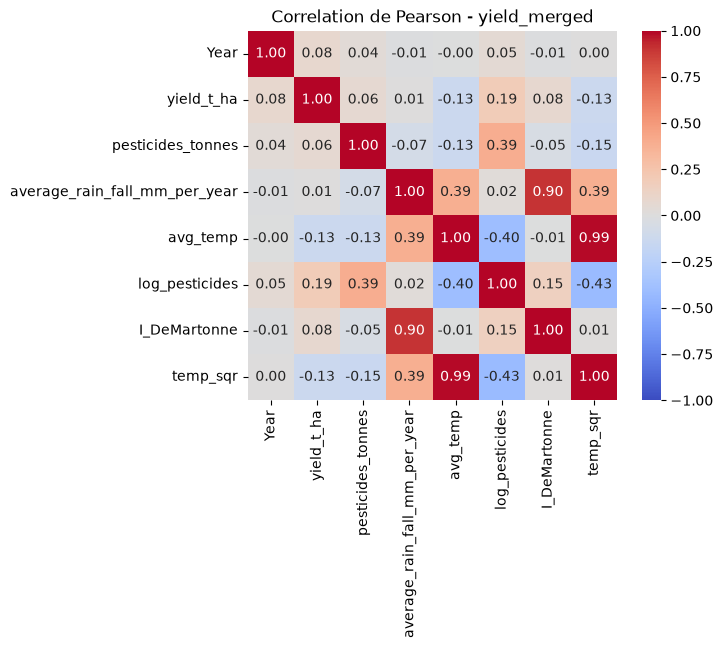

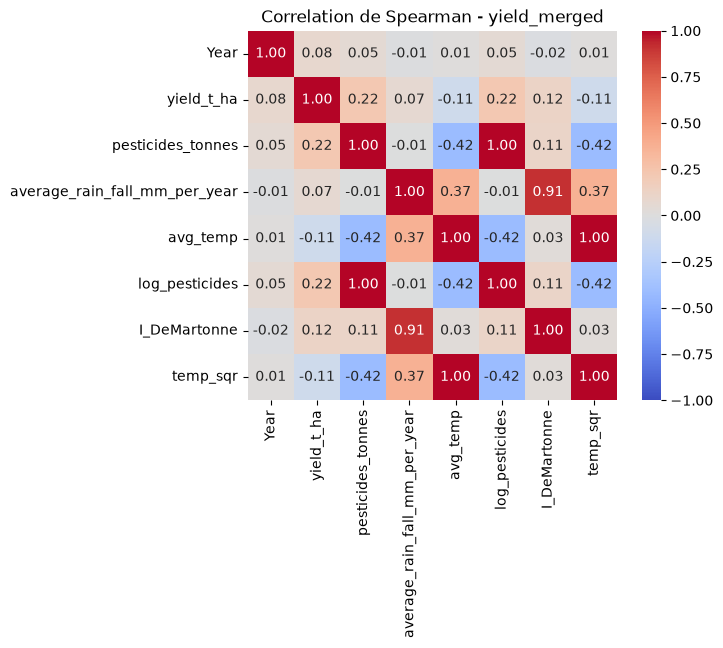

In [38]:
#Verifications des corrélations avec les nouvelles variables
corr_matrix_P_yield_FE = yield_merged.corr(method="pearson", numeric_only=True)
corr_matrix_S_yield_FE = yield_merged.corr(method ="spearman", numeric_only=True)
sns.heatmap(
    data=corr_matrix_P_yield_FE,
    cmap="coolwarm",
    square=True,
    vmin=-1,
    vmax=1,
    center=0,
    annot= True,
    fmt=".2f" 
)
plt.title("Correlation de Pearson - yield_merged")
plt.show()

sns.heatmap(
    data=corr_matrix_S_yield_FE,
    cmap="coolwarm",
    square=True,
    vmin=-1,
    vmax=1,
    center=0,
    annot= True,
    fmt=".2f" 
)
plt.title("Correlation de Spearman - yield_merged")
plt.show()

Pour le moment, seul pesticides_tonnes sera supprimé. Les autres sont conservés pour le moment et seront supprimé lors des tests des modèles. En fonction des résultats des métriques avec ou sans ces valeurs, nous supprimerons ou non ces variables pour alléger le modèle choisi.

In [39]:
# Export du dataset consolidé : la source de vérité pour la modélisation
dataset_consolide = yield_merged.drop(columns=["pesticides_tonnes"])  # remplacée par log_pesticides

print(dataset_consolide.shape)
print(dataset_consolide.columns.tolist())

dataset_consolide.to_csv(DATA_FILE / "dataset_consolide.csv", index=False)

(16397, 9)
['Area', 'Crop', 'Year', 'yield_t_ha', 'average_rain_fall_mm_per_year', 'avg_temp', 'log_pesticides', 'I_DeMartonne', 'temp_sqr']
